# Locked Test Prediction

Frozen models are applied to the test windows of both protocols; no test metric is computed in this section. Predictions are produced for the six frozen Notebook 04 models (GlucoBench linear regression, Sparacino AR(1)-WLS, persistence, 30-min linear trend, Ridge and shallow GBT on the Notebook 03 glucose-history features) on all admitted test windows, and for the 46 locked Notebook 05 experiments on the test windows of their locked cohorts. Models are loaded only through their registered fit keys and are never refitted or retuned (no train+validation refit).

In [1]:
# --- Import dependencies ---

import json

import joblib
import os

# Fix the physical-core count so joblib/loky does not emit a non-actionable Windows detection warning.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.dates import DateFormatter

from src.paths import PROJECT_ROOT

# --- Configure artifact directories ---


BASELINE_DIR = PROJECT_ROOT / "artifacts" / "04_baseline_models"
ABLATION_DIR = PROJECT_ROOT / "artifacts" / "05_factor_ablation"
EVAL_DIR = PROJECT_ROOT / "artifacts" / "06_evaluation_report"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# --- Configure compact tabular displays ---

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


In [2]:
# Load the baseline registry and selected ablation experiments once for evaluation.
baseline_registry = json.loads((BASELINE_DIR / "baseline_registry.json").read_text(encoding="utf-8"))
lock = json.loads((ABLATION_DIR / "locked_experiments.json").read_text(encoding="utf-8"))
locked = pd.DataFrame(lock["experiments"])

upstream_paths = baseline_registry["upstream_paths"]
WINDOW_KEY = baseline_registry["sample_keys"]["window_key"]
FOLD_KEY = baseline_registry["sample_keys"]["fold_key"]
PROTOCOLS = [baseline_registry["protocol_names"]["A"], baseline_registry["protocol_names"]["B"]]
HORIZON_MIN = baseline_registry["task"]["forecast_horizon_minutes"]
TASK_ID = baseline_registry["task"]["task_id"]
TARGET_FIELD = baseline_registry["task"]["target_field"]

# Notebook 03 split: admitted validation and test windows of each protocol; validation windows are loaded only
# so the isolation check below can confirm no validation window appears in the assembled test predictions.
folds = pd.read_parquet(PROJECT_ROOT / upstream_paths["fold_assignments"], columns=FOLD_KEY + ["split", "admitted_to_split"])
folds = folds.loc[folds["admitted_to_split"] & folds["split"].isin(["validation", "test"])].drop(columns="admitted_to_split")
test_keys = folds.loc[folds["split"].eq("test")]
print(f"Locked experiments: {len(locked)}; frozen Notebook 04 models: "
      f"{sum(len(m) for m in baseline_registry['models'].values())}")
display(test_keys.groupby("evaluation_protocol").agg(windows=("subject", "size"), subjects=("subject", "nunique")))


Locked experiments: 46; frozen Notebook 04 models: 6


,windows,subjects
evaluation_protocol,,
Unseen-subject Generalization,28322,9
Within-subject Future Prediction,26269,45


In [3]:
# Prediction-time inputs for validation and test windows, all from upstream artifacts.
samples = pd.read_parquet(PROJECT_ROOT / upstream_paths["glucose_history_samples"])
glucose_feature_registry = pd.read_csv(PROJECT_ROOT / upstream_paths["feature_registry"])
G_FEATURES = glucose_feature_registry.loc[glucose_feature_registry["allowed_as_predictor"], "feature_name"].tolist()
activity_diet = pd.read_parquet(ABLATION_DIR / "activity_diet_features.parquet")
static = pd.read_parquet(ABLATION_DIR / "static_features.parquet")
cohorts = pd.read_parquet(ABLATION_DIR / "comparison_cohorts.parquet")
fold_cohorts = cohorts[FOLD_KEY + ["split", "cohort_core", "cohort_gut", "cohort_full"]]

# Raw glucose lags for the frozen GlucoBench LR (5-min) and Sparacino (3-min) inputs, gathered at offsets <= 0.
lag_offsets = sorted({int(c[1:]) for m in ("glucobench_linear_regression", "sparacino2007_ar1_wls")
                      for p in baseline_registry["models"]["formal baseline reproduction"][m]["protocols"].values() for c in p["inputs"]})
assert max(lag_offsets) == 0
grid = pd.read_parquet(PROJECT_ROOT / upstream_paths["base_grid"], columns=["subject", "timestamp", TARGET_FIELD, "dexcom_gl"])
grid = grid.sort_values(["subject", "timestamp"])
assert grid.groupby("subject")["timestamp"].diff().dropna().eq(pd.Timedelta(minutes=1)).all()
start = grid.groupby("subject")["timestamp"].first()
values = {s: part[TARGET_FIELD].to_numpy() for s, part in grid.groupby("subject")}
windows = folds[WINDOW_KEY].drop_duplicates().reset_index(drop=True)
position = ((windows["origin_time"] - windows["subject"].map(start)) // pd.Timedelta(minutes=1)).to_numpy()
lags = np.empty((len(windows), len(lag_offsets)))
for s, idx in windows.groupby("subject").indices.items():
    lags[idx] = values[s][position[idx][:, None] + np.array(lag_offsets)[None, :]]
assert np.isfinite(lags).all()
windows = pd.concat([windows, pd.DataFrame(lags, columns=[f"g{o}" for o in lag_offsets])], axis=1)

# One modelling frame per (protocol, window) for validation and test rows.
frame = (folds.merge(fold_cohorts, on=FOLD_KEY + ["split"], how="left", validate="one_to_one")
         .merge(samples[WINDOW_KEY + ["target_time", "target_value"] + G_FEATURES], on=WINDOW_KEY, how="left", validate="many_to_one")
         .merge(windows, on=WINDOW_KEY, how="left", validate="many_to_one")
         .merge(activity_diet, on=WINDOW_KEY, how="left", validate="many_to_one")
         .merge(static, on="subject", how="left", validate="many_to_one"))
assert frame["target_value"].notna().all() and frame[["cohort_core", "cohort_gut", "cohort_full"]].notna().all().all()
# Lag cross-check against the registered exact-lag features.
for minutes in (0, 30, 60, 120):
    if f"g{-minutes}" in frame:
        assert np.allclose(frame[f"g{-minutes}"], frame[f"glucose_lag_{minutes}min"], rtol=0, atol=1e-9)
print(f"Prediction frame: {frame.shape}; lag offsets gathered: {len(lag_offsets)}")


Prediction frame: (105180, 242); lag offsets gathered: 57


In [4]:
# Frozen Notebook 04 models: formal baselines, simple references and project comparisons (no refitting).
baseline_fits = joblib.load(BASELINE_DIR / "baseline_fits.joblib")["fits"]

def predict_baseline(model_id: str, protocol: str, part: pd.DataFrame) -> np.ndarray:
    entry = next(g[model_id]["protocols"][protocol] for g in baseline_registry["models"].values() if model_id in g)
    fit = baseline_fits[entry["fit_key"]]
    if model_id == "sparacino2007_ar1_wls":
        u = part[entry["inputs"]].to_numpy()
        weights = entry["params"]["mu"] ** np.arange(u.shape[1] - 2, -1, -1)
        a = (weights * u[:, :-1] * u[:, 1:]).sum(axis=1) / (weights * u[:, :-1] ** 2).sum(axis=1)
        return a ** entry["params"]["T"] * u[:, -1]
    if model_id == "glucobench_linear_regression":
        scaler, columns = fit["scaler"], entry["inputs"]
        scaled = scaler.transform(part[columns].to_numpy().reshape(-1, 1)).reshape(-1, len(columns))
        return scaler.inverse_transform(fit["model"].predict(scaled).reshape(-1, 1)).ravel()
    features = part[entry["inputs"]]
    return fit["model"].predict(fit["scaler"].transform(features) if fit["scaler"] is not None else features)
def predict_reference(reference: str, part: pd.DataFrame) -> np.ndarray:
    if reference == "persistence":
        return part["glucose_lag_0min"].to_numpy()
    return (part["glucose_lag_0min"] + HORIZON_MIN * part["glucose_slope_30min"]).to_numpy()


# Test predictions for every frozen Notebook 04 model on all admitted test windows of each protocol.
# Each prediction is generated directly from the registry-declared fit_key and inputs (an incorrect key or
# input set would raise KeyError or fail the coverage/finiteness checks below); no separate reload-and-
# revalidate-on-validation-data reproduction step is performed here.
category_of = {m: g for g, models in baseline_registry["models"].items() for m in models}
prediction_frames = []
for model_id, category in category_of.items():
    for protocol in PROTOCOLS:
        part = frame.loc[frame["evaluation_protocol"].eq(protocol) & frame["split"].eq("test")]
        if category == "simple reference":
            prediction, fit_key, config = predict_reference(model_id, part), "none (no parameters)", "no parameters"
        else:
            entry = baseline_registry["models"][category][model_id]["protocols"][protocol]
            prediction, fit_key, config = predict_baseline(model_id, protocol, part), entry["fit_key"], entry["config"]
        prediction_frames.append(part[FOLD_KEY + ["target_time", "target_value"]].assign(
            source="baseline registry", model_id=model_id, experiment_id=f"baseline|{model_id}|{protocol}",
            category=category, config=config, cohort="all test windows", family=model_id, fit_key=fit_key,
            prediction=prediction))
print(f"Notebook 04 models predicted: {len(category_of)} x {len(PROTOCOLS)} protocols")


Notebook 04 models predicted: 6 x 2 protocols


Notebook 04 models cover all admitted test windows; comparisons with locked experiments are restricted to shared windows.

In [5]:
# Locked Notebook 05 ablation experiments: stored training-split fits applied to test rows of their locked cohort (no refitting).
ablation_fits = joblib.load(ABLATION_DIR / "ablation_fits.joblib")["fits"]
for row in locked.itertuples(index=False):
    fit = ablation_fits[row.fit_key]
    # Test predictions on the locked cohort, directly from the registry-declared fit_key, cohort and inputs.
    part = frame.loc[frame["evaluation_protocol"].eq(row.evaluation_protocol) & frame["split"].eq("test") & frame[row.cohort]]
    prediction_frames.append(part[FOLD_KEY + ["target_time", "target_value"]].assign(
        source="locked experiments", model_id=row.config_id, experiment_id=row.experiment_id, category=row.tier,
        config=f"{row.feature_groups} | {row.hyperparameters}", cohort=row.cohort, family=row.family, fit_key=row.fit_key,
        prediction=fit["model"].predict(part[fit["inputs"]])))
print(f"Locked experiments predicted: {len(locked)}")


Locked experiments predicted: 46


In [6]:
# --- Assemble frozen test predictions ---

test_predictions = pd.concat(prediction_frames, ignore_index=True)

# --- Validate prediction integrity and cohort coverage ---

assert test_predictions.merge(test_keys, on=FOLD_KEY, how="left", indicator=True)["_merge"].eq("both").all()
assert test_predictions.merge(folds.loc[folds["split"].eq("validation"), FOLD_KEY], on=FOLD_KEY).empty
assert not test_predictions.duplicated(["experiment_id"] + FOLD_KEY).any()
assert np.isfinite(test_predictions["prediction"]).all()

# Coverage: frozen Notebook 04 models cover every test window; locked experiments cover exactly their locked cohort's test windows.
coverage = test_predictions.groupby(["experiment_id", "evaluation_protocol", "cohort"]).size().rename("windows").reset_index()
expected = {c: cohorts.loc[cohorts["split"].eq("test") & cohorts[c]].groupby("evaluation_protocol").size() for c in ["cohort_core", "cohort_gut", "cohort_full"]}
expected["all test windows"] = test_keys.groupby("evaluation_protocol").size()
coverage["expected"] = [int(expected[c][p]) for c, p in zip(coverage["cohort"], coverage["evaluation_protocol"])]
assert coverage["windows"].eq(coverage["expected"]).all()
assert set(locked["experiment_id"]) <= set(test_predictions["experiment_id"])
assert test_predictions.loc[test_predictions["source"].eq("baseline registry"), "model_id"].nunique() == len(category_of)

# --- Verify causal feature inputs ---

inputs_used = set().union(*[set(ablation_fits[k]["inputs"]) for k in locked["fit_key"]])
allowed_inputs = set(G_FEATURES) | set(activity_diet.columns) | set(static.columns)
assert inputs_used <= allowed_inputs

display(test_predictions.groupby(["source", "evaluation_protocol"]).agg(experiments=("experiment_id", "nunique"), rows=("prediction", "size")))


experiments    rows
source             evaluation_protocol                                  
baseline registry  Unseen-subject Generalization               6  169932
                   Within-subject Future Prediction            6  157614
locked experiments Unseen-subject Generalization              23  619273
                   Within-subject Future Prediction           23  522812

Each locked experiment covers exactly the test windows of its locked cohort. No error metric is computed here.

In [7]:
# Persist the standardized test-prediction table.
columns = ["task_id", "evaluation_protocol", "subject", "origin_time", "target_time", "target_value", "prediction",
           "source", "category", "model_id", "experiment_id", "config", "cohort", "family", "fit_key"]
test_predictions = test_predictions[columns]
test_predictions.to_parquet(EVAL_DIR / "test_predictions.parquet", index=False)


- `test_predictions.parquet` (1,469,631 × 15) holds one row per experiment, protocol and test window: 157,614 (A) and 169,932 (B) rows for the six frozen Notebook 04 models on all admitted test windows, and 522,812 (A) and 619,273 (B) rows for the 46 locked experiments on their locked cohorts.
- Checks confirm that keys are admitted Notebook 03 test windows only, there are no duplicates, coverage equals the locked cohort rules, inputs come from the registered features at or before the origin, and no validation-split window appears in the assembled test predictions.


# Subject-Level and Pooled Metrics

This section reuses the frozen test predictions above without refitting, re-predicting or tuning; no paired comparison or uncertainty estimate is made here. For each experiment, MAE and RMSE are first computed per subject (`metrics_by_subject`). Two distinct aggregates are then reported (`metrics_summary`): `subject_equal_*`, the equal-weight mean of per-subject metrics (primary), and `pooled_window_*`, computed over all windows together (secondary). Each summary row also reports effective subjects, total windows and windows per subject. The two protocols are summarised separately.


In [8]:
# Expected coverage: the admitted Notebook 03 test windows (frozen Notebook 04 models) and the locked test sample (each cohort).
expected_sample = {(p, "all test windows"): (int(g["subject"].size), int(g["subject"].nunique())) for p, g in test_keys.groupby("evaluation_protocol")}
expected_sample.update({(s["evaluation_protocol"], s["cohort"]): (s["windows"], s["subjects"]) for s in lock["test_sample"]})

# Expected experiment list: every frozen Notebook 04 model under both protocols plus every locked Notebook 05 experiment.
expected_experiments = pd.concat([
    pd.DataFrame([{"experiment_id": f"baseline|{model_id}|{protocol}", "evaluation_protocol": protocol, "cohort": "all test windows"}
                  for models in baseline_registry["models"].values() for model_id in models for protocol in PROTOCOLS]),
    locked[["experiment_id", "evaluation_protocol", "cohort"]],
], ignore_index=True)
expected_experiments[["expected_windows", "expected_subjects"]] = [expected_sample[(p, c)] for p, c in
                                                                   zip(expected_experiments["evaluation_protocol"], expected_experiments["cohort"])]
print(f"Expected experiments: {len(expected_experiments)} "
      f"({sum(len(m) for m in baseline_registry['models'].values())} frozen Notebook 04 models x {len(PROTOCOLS)} protocols + {len(locked)} locked)")


Expected experiments: 58 (6 frozen Notebook 04 models x 2 protocols + 46 locked)


In [9]:
# Per-subject test errors (mg/dL) for every experiment; error = prediction - target.
ID_COLS = ["evaluation_protocol", "source", "category", "model_id", "experiment_id", "config", "cohort", "family"]
rows = test_predictions.assign(error=test_predictions["prediction"] - test_predictions["target_value"])
rows["abs_error"] = rows["error"].abs()
rows["squared_error"] = rows["error"] ** 2
metrics_by_subject = (rows.groupby(ID_COLS + ["subject"], sort=False)
                      .agg(n_windows=("error", "size"), first_origin_time=("origin_time", "min"), last_origin_time=("origin_time", "max"),
                           sum_abs_error=("abs_error", "sum"), sum_squared_error=("squared_error", "sum"))
                      .reset_index())
metrics_by_subject["mae"] = metrics_by_subject["sum_abs_error"] / metrics_by_subject["n_windows"]
metrics_by_subject["rmse"] = np.sqrt(metrics_by_subject["sum_squared_error"] / metrics_by_subject["n_windows"])
experiment_order = {e: i for i, e in enumerate(test_predictions["experiment_id"].unique())}
metrics_by_subject = (metrics_by_subject.assign(order=metrics_by_subject["experiment_id"].map(experiment_order))
                      .sort_values(["order", "subject"]).drop(columns="order").reset_index(drop=True))


In [10]:
# Two distinct aggregates per experiment:
#   subject_equal_*  = mean over subjects of the per-subject MAE / RMSE (each subject weighted equally; primary)
#   pooled_window_*  = MAE / RMSE over all windows together (each window weighted equally; secondary)
grouped = metrics_by_subject.groupby(ID_COLS, sort=False)
metrics_summary = grouped.agg(
    n_subjects=("subject", "nunique"), n_windows=("n_windows", "sum"),
    windows_per_subject_min=("n_windows", "min"), windows_per_subject_median=("n_windows", "median"), windows_per_subject_max=("n_windows", "max"),
    subject_equal_mae=("mae", "mean"), subject_equal_rmse=("rmse", "mean"),
    sum_abs_error=("sum_abs_error", "sum"), sum_squared_error=("sum_squared_error", "sum"),
).reset_index()
metrics_summary["pooled_window_mae"] = metrics_summary["sum_abs_error"] / metrics_summary["n_windows"]
metrics_summary["pooled_window_rmse"] = np.sqrt(metrics_summary["sum_squared_error"] / metrics_summary["n_windows"])
metrics_summary = metrics_summary.drop(columns=["sum_abs_error", "sum_squared_error"])
SHOW = ["category", "experiment", "cohort", "n_subjects", "n_windows", "windows_per_subject_min", "windows_per_subject_median",
        "windows_per_subject_max", "subject_equal_mae", "subject_equal_rmse", "pooled_window_mae", "pooled_window_rmse"]
for protocol in PROTOCOLS:
    print(f"\n{protocol}  (mg/dL; subject_equal = mean of per-subject metrics, pooled_window = all windows together)")
    display(metrics_summary.loc[metrics_summary["evaluation_protocol"].eq(protocol)]
            .assign(experiment=lambda d: np.where(d["source"].eq("baseline registry"), d["model_id"],
                                                  d["model_id"] + " | " + d["family"]))[SHOW]
            .round(3).reset_index(drop=True))



Within-subject Future Prediction  (mg/dL; subject_equal = mean of per-subject metrics, pooled_window = all windows together)


,category,experiment,cohort,n_subjects,n_windows,windows_per_subject_min,windows_per_subject_median,windows_per_subject_max,subject_equal_mae,subject_equal_rmse,pooled_window_mae,pooled_window_rmse
0,formal baseline reproduction,glucobench_linear_regression,all test windows,45,26269,40,562.0,1074,7.389,10.832,7.322,10.919
1,formal baseline reproduction,sparacino2007_ar1_wls,all test windows,45,26269,40,562.0,1074,10.599,16.633,10.711,17.114
2,simple reference,persistence,all test windows,45,26269,40,562.0,1074,10.038,15.018,10.125,15.563
3,simple reference,linear_trend_30min,all test windows,45,26269,40,562.0,1074,13.037,19.264,13.218,19.829
4,project comparison,ridge_glucose_history_features,all test windows,45,26269,40,562.0,1074,7.692,11.187,7.632,11.297
5,project comparison,shallow_gbt_glucose_history_features,all test windows,45,26269,40,562.0,1074,9.047,13.057,9.067,13.362
6,primary,G | ridge,cohort_core,44,21083,40,539.5,1074,7.817,11.300,7.744,11.442
7,primary,G+A | ridge,cohort_core,44,21083,40,539.5,1074,7.769,11.319,7.745,11.442
8,primary,G+A+D | ridge,cohort_core,44,21083,40,539.5,1074,7.718,11.287,7.683,11.405
9,primary,G+A+D+B | ridge,cohort_core,44,21083,40,539.5,1074,7.746,11.292,7.699,11.415



Unseen-subject Generalization  (mg/dL; subject_equal = mean of per-subject metrics, pooled_window = all windows together)


,category,experiment,cohort,n_subjects,n_windows,windows_per_subject_min,windows_per_subject_median,windows_per_subject_max,subject_equal_mae,subject_equal_rmse,pooled_window_mae,pooled_window_rmse
0,formal baseline reproduction,glucobench_linear_regression,all test windows,9,28322,2832,3138.0,3420,7.427,11.222,7.430,11.269
1,formal baseline reproduction,sparacino2007_ar1_wls,all test windows,9,28322,2832,3138.0,3420,10.546,17.930,10.565,18.101
2,simple reference,persistence,all test windows,9,28322,2832,3138.0,3420,9.922,15.265,9.888,15.509
3,simple reference,linear_trend_30min,all test windows,9,28322,2832,3138.0,3420,12.798,19.455,12.796,19.608
4,project comparison,ridge_glucose_history_features,all test windows,9,28322,2832,3138.0,3420,7.635,11.374,7.638,11.404
5,project comparison,shallow_gbt_glucose_history_features,all test windows,9,28322,2832,3138.0,3420,8.940,13.271,8.944,13.435
6,primary,G | ridge,cohort_core,9,26861,2829,2926.0,3406,7.701,11.475,7.712,11.515
7,primary,G+A | ridge,cohort_core,9,26861,2829,2926.0,3406,7.677,11.440,7.689,11.481
8,primary,G+A+D | ridge,cohort_core,9,26861,2829,2926.0,3406,7.493,11.169,7.507,11.221
9,primary,G+A+D+B | ridge,cohort_core,9,26861,2829,2926.0,3406,7.429,11.125,7.441,11.174


Subject-equal and pooled-window metrics differ because pooled metrics weight subjects by their number of windows. Experiments on different cohorts cover different windows, so values here are not compared; paired comparisons on shared windows follow in the Paired Gains and Uncertainty section.

In [11]:
# Coverage: the experiment set and each experiment's windows / subjects equal the frozen registries and the prediction rows.
summary_vs_expected = metrics_summary.merge(expected_experiments, on="experiment_id", how="outer", suffixes=("", "_expected"), indicator=True)
assert summary_vs_expected["_merge"].eq("both").all() and len(metrics_summary) == len(expected_experiments)
assert (summary_vs_expected["evaluation_protocol"].eq(summary_vs_expected["evaluation_protocol_expected"]).all()
        and summary_vs_expected["cohort"].eq(summary_vs_expected["cohort_expected"]).all())
assert (summary_vs_expected["n_windows"].eq(summary_vs_expected["expected_windows"]).all()
        and summary_vs_expected["n_subjects"].eq(summary_vs_expected["expected_subjects"]).all())
assert metrics_summary.set_index("experiment_id")["n_windows"].eq(test_predictions.groupby("experiment_id").size()).all()
assert metrics_by_subject["n_windows"].sum() == len(test_predictions) and not metrics_by_subject.duplicated(["experiment_id", "subject"]).any()

gap = (metrics_summary["subject_equal_rmse"] - metrics_summary["pooled_window_rmse"]).abs()
print(f"|subject_equal_rmse - pooled_window_rmse| across experiments: min {gap.min():.3f}, max {gap.max():.3f} mg/dL")


|subject_equal_rmse - pooled_window_rmse| across experiments: min 0.018, max 0.564 mg/dL


The experiment set, protocols, cohorts, window counts and subject counts are checked against the frozen coverage.


In [12]:
# Persist subject-level and summary metrics.
metrics_by_subject.to_csv(EVAL_DIR / "metrics_by_subject.csv", index=False)
metrics_summary.to_csv(EVAL_DIR / "metrics_summary.csv", index=False)

- `metrics_by_subject.csv` (1,539 × 16) holds per-subject MAE, RMSE, window counts and error sums for every experiment and subject: 1,281 rows for Protocol A and 258 for Protocol B.
- `metrics_summary.csv` (58 × 17, 29 experiments per protocol) holds effective subjects, total windows, windows per subject (min, median, max), subject-equal MAE/RMSE and pooled-window MAE/RMSE.
- The experiment set, protocols, cohorts, window counts and subject counts equal the frozen coverage.


# Paired Gains and Uncertainty

The 42 locked contrasts from the Notebook 05 lock (21 per protocol) are compared on the fixed test predictions above (frozen, as in the Locked Test Prediction section); the contrast list is unchanged. Both sides of a contrast use identical subjects and window keys. Deltas are to minus from (negative = lower error in the 'to' experiment), computed per subject and averaged with equal subject weight. The improved share is the proportion of subjects with lower RMSE, and pooled-window deltas are reported separately. Uncertainty uses the frozen subject-level paired cluster bootstrap (2,000 resamples, seed 42, 95% percentile interval): subjects are drawn with replacement and each drawn subject contributes all of its windows to both sides. Windows are never resampled individually. The intervals describe subject sampling for fixed predictions only and do not include uncertainty from retraining the models.


In [13]:
# Uncertainty settings and outcome rule from the Notebook 05 lock (not changed after seeing test results).
BOOT = lock["evaluation"]["uncertainty"]
N_RESAMPLES, SEED, CI_LEVEL = int(BOOT["resamples"]), int(BOOT["seed"]), float(BOOT["interval_level"])
NEGLIGIBLE_MG_DL = lock["evaluation"]["outcome_rule"]["negligible_mg_dl"]


# Locked contrasts, each side resolved to exactly one locked experiment (config, cohort, family, protocol).
def locked_experiment(config_id, cohort, family, protocol):
    rows = locked.loc[locked["config_id"].eq(config_id) & locked["cohort"].eq(cohort)
                      & locked["family"].eq(family) & locked["evaluation_protocol"].eq(protocol), "experiment_id"]
    assert len(rows) == 1, (config_id, cohort, family, protocol)
    return rows.iloc[0]


contrasts = pd.DataFrame(lock["contrasts"])
contrasts["experiment_id_from"] = [locked_experiment(c.config_from, c.cohort, c.family_from, c.evaluation_protocol) for c in contrasts.itertuples()]
contrasts["experiment_id_to"] = [locked_experiment(c.config_to, c.cohort, c.family_to, c.evaluation_protocol) for c in contrasts.itertuples()]
print(f"Locked contrasts: {len(contrasts)}; bootstrap: {BOOT['method']}, {N_RESAMPLES} resamples, seed {SEED}, {CI_LEVEL:.0%} {BOOT['interval_type']} interval")
display(contrasts.groupby(["evaluation_protocol", "block"], sort=False).size().rename("contrasts").to_frame())


Locked contrasts: 42; bootstrap: subject-level paired cluster bootstrap (all windows of a subject resampled together), 2000 resamples, seed 42, 95% percentile interval


contrasts
evaluation_protocol              block                                  
Within-subject Future Prediction core                                  7
                                 missing_handling_all_windows          7
                                 sensitivity                           2
                                 gut_optional                          3
                                 structure_x_feature_group             2
Unseen-subject Generalization    core                                  7
                                 missing_handling_all_windows          7
                                 sensitivity                           2
                                 gut_optional                          3
                                 structure_x_feature_group             2

In [14]:
# Paired per-subject deltas (to minus from; negative = lower error in the 'to' experiment) on identical test windows.
predictions_by_experiment = {e: g[FOLD_KEY + ["target_value", "prediction"]] for e, g in test_predictions.groupby("experiment_id", sort=False)}
subject_rows = {e: g.set_index("subject") for e, g in metrics_by_subject.groupby("experiment_id", sort=False)}
paired = {}
for c in contrasts.itertuples():
    a, b = predictions_by_experiment[c.experiment_id_from], predictions_by_experiment[c.experiment_id_to]
    m = a.merge(b, on=FOLD_KEY, how="outer", suffixes=("_from", "_to"), validate="one_to_one", indicator=True)
    # Both sides of a contrast use identical window keys, targets, subjects and protocol.
    assert m["_merge"].eq("both").all() and len(m) == len(a) == len(b)
    assert np.array_equal(m["target_value_from"], m["target_value_to"])
    m = m.sort_values(["subject", "origin_time"]).reset_index(drop=True)
    m["err_from"] = m["prediction_from"] - m["target_value_from"]
    m["err_to"] = m["prediction_to"] - m["target_value_to"]
    s_from, s_to = subject_rows[c.experiment_id_from], subject_rows[c.experiment_id_to]
    subjects = s_from.index.sort_values()
    assert subjects.equals(s_to.index.sort_values()) and subjects.equals(pd.Index(np.sort(m["subject"].unique())))
    assert set(s_from["evaluation_protocol"]) == set(s_to["evaluation_protocol"]) == {c.evaluation_protocol}
    paired[(c.block, c.contrast_id, c.evaluation_protocol)] = {
        "subjects": subjects.to_numpy(), "windows": m[["subject", "err_from", "err_to"]],
        "d_mae": (s_to.loc[subjects, "mae"] - s_from.loc[subjects, "mae"]).to_numpy(),
        "d_rmse": (s_to.loc[subjects, "rmse"] - s_from.loc[subjects, "rmse"]).to_numpy(),
        "sums": {side: s.loc[subjects, ["n_windows", "sum_abs_error", "sum_squared_error"]].to_numpy() for side, s in (("from", s_from), ("to", s_to))},
    }
print(f"Paired contrasts: {len(paired)}")


Paired contrasts: 42


In [15]:
# Subject-level paired cluster bootstrap on the fixed test predictions: subjects are drawn with replacement and each drawn
# subject contributes all of its windows to both sides of the contrast; windows are never resampled individually.
def draw_subjects(n_subjects):
    return np.random.default_rng(SEED).integers(0, n_subjects, size=(N_RESAMPLES, n_subjects))


def replicate_statistics(p, draws):
    d_mae, d_rmse = p["d_mae"][draws], p["d_rmse"][draws]
    out = {"d_mae": d_mae.mean(axis=1), "d_rmse": d_rmse.mean(axis=1), "improved_share": (d_rmse < 0).mean(axis=1)}
    pooled = {side: p["sums"][side][draws].sum(axis=1) for side in ("from", "to")}
    out["pooled_window_d_rmse"] = (np.sqrt(pooled["to"][:, 2] / pooled["to"][:, 0]) - np.sqrt(pooled["from"][:, 2] / pooled["from"][:, 0]))
    return out


alpha = (1 - CI_LEVEL) / 2
rows, replicates = [], {}
for c in contrasts.itertuples():
    key = (c.block, c.contrast_id, c.evaluation_protocol)
    p = paired[key]
    draws = draw_subjects(len(p["subjects"]))
    stats = replicate_statistics(p, draws)
    replicates[key] = stats
    sums = {side: p["sums"][side].sum(axis=0) for side in ("from", "to")}
    point = {"d_mae": p["d_mae"].mean(), "d_rmse": p["d_rmse"].mean(), "improved_share": (p["d_rmse"] < 0).mean(),
             "pooled_window_d_rmse": np.sqrt(sums["to"][2] / sums["to"][0]) - np.sqrt(sums["from"][2] / sums["from"][0])}
    row = {"block": c.block, "contrast_id": c.contrast_id, "contrast": c.contrast, "group_tested": c.group_tested,
           "evaluation_protocol": c.evaluation_protocol, "cohort": c.cohort, "family_from": c.family_from, "family_to": c.family_to,
           "config_from": c.config_from, "config_to": c.config_to, "experiment_id_from": c.experiment_id_from, "experiment_id_to": c.experiment_id_to,
           "n_subjects": len(p["subjects"]), "n_windows": int(sums["to"][0]),
           "subject_equal_rmse_from": metrics_summary.set_index("experiment_id").at[c.experiment_id_from, "subject_equal_rmse"],
           "subject_equal_rmse_to": metrics_summary.set_index("experiment_id").at[c.experiment_id_to, "subject_equal_rmse"]}
    for name, value in point.items():
        low, high = np.percentile(stats[name], [100 * alpha, 100 * (1 - alpha)])
        row.update({name: value, f"{name}_ci_low": low, f"{name}_ci_high": high})
    row.update({"median_d_rmse": np.median(p["d_rmse"]), "improved_subjects": int((p["d_rmse"] < 0).sum()),
                "worsened_subjects": int((p["d_rmse"] > 0).sum()),
                "pooled_window_d_mae": sums["to"][1] / sums["to"][0] - sums["from"][1] / sums["from"][0]})
    rows.append(row)
paired_gain_intervals = pd.DataFrame(rows)


# Pre-specified Notebook 05 outcome rule applied to the point estimates; the validation label is kept for reference only.
def classify(d_rmse, improved_share):
    if abs(d_rmse) < NEGLIGIBLE_MG_DL:
        return "negligible"
    if d_rmse < 0 and improved_share > 0.5:
        return "improved"
    if d_rmse > 0 and improved_share < 0.5:
        return "worse"
    return "mixed"

paired_gain_intervals["test_outcome"] = [classify(d, s) for d, s in zip(paired_gain_intervals["d_rmse"], paired_gain_intervals["improved_share"])]
paired_gain_intervals["d_rmse_ci_excludes_zero"] = (paired_gain_intervals["d_rmse_ci_high"] < 0) | (paired_gain_intervals["d_rmse_ci_low"] > 0)
paired_gain_intervals["validation_outcome"] = contrasts["validation_outcome"].to_numpy()
paired_gain_intervals = paired_gain_intervals.assign(
    bootstrap_method=BOOT["method"], bootstrap_unit="subject", bootstrap_resamples=N_RESAMPLES, bootstrap_seed=SEED, ci_level=CI_LEVEL,
    ci_method=f"{CI_LEVEL:.0%} {BOOT['interval_type']}",
    uncertainty_scope="fixed test predictions; subject sampling only; excludes model retraining variability")
SHOW = ["block", "contrast_id", "contrast", "n_subjects", "d_mae", "d_mae_ci_low", "d_mae_ci_high", "d_rmse", "d_rmse_ci_low", "d_rmse_ci_high",
        "improved_subjects", "improved_share", "improved_share_ci_low", "improved_share_ci_high", "pooled_window_d_rmse", "test_outcome", "validation_outcome"]
for protocol in PROTOCOLS:
    print(f"\n{protocol}  (mg/dL; delta = to - from, negative = lower error; {int(CI_LEVEL * 100)}% subject-cluster bootstrap intervals)")
    display(paired_gain_intervals.loc[paired_gain_intervals["evaluation_protocol"].eq(protocol), SHOW].round(3).reset_index(drop=True))


Within-subject Future Prediction  (mg/dL; delta = to - from, negative = lower error; 95% subject-cluster bootstrap intervals)


,block,contrast_id,contrast,n_subjects,d_mae,d_mae_ci_low,d_mae_ci_high,d_rmse,d_rmse_ci_low,d_rmse_ci_high,improved_subjects,improved_share,improved_share_ci_low,improved_share_ci_high,pooled_window_d_rmse,test_outcome,validation_outcome
0,core,G->G+A,G -> G+A (incremental; single_group_addition),44,-0.048,-0.157,0.035,0.019,-0.056,0.107,23,0.523,0.386,0.682,0.001,negligible,negligible
1,core,G+A->G+A+D,G+A -> G+A+D (incremental),44,-0.051,-0.124,0.023,-0.032,-0.142,0.070,23,0.523,0.364,0.682,-0.038,negligible,improved
2,core,G+A+D->G+A+D+B,G+A+D -> G+A+D+B (incremental; leave_one_group...,44,0.028,-0.045,0.118,0.005,-0.050,0.068,27,0.614,0.477,0.750,0.010,negligible,negligible
3,core,G->G+D,G -> G+D (single_group_addition),44,-0.073,-0.145,-0.002,-0.041,-0.148,0.062,23,0.523,0.386,0.682,-0.039,negligible,improved
4,core,G->G+B,G -> G+B (single_group_addition),44,0.036,-0.032,0.120,-0.012,-0.056,0.041,30,0.682,0.545,0.818,-0.010,negligible,negligible
5,core,G+D+B->G+A+D+B,G+D+B -> G+A+D+B (leave_one_group_out),44,-0.035,-0.179,0.059,0.046,-0.028,0.131,22,0.500,0.341,0.659,0.017,negligible,mixed
6,core,G+A+B->G+A+D+B,G+A+B -> G+A+D+B (leave_one_group_out),44,-0.043,-0.118,0.032,-0.028,-0.140,0.077,22,0.500,0.341,0.659,-0.033,negligible,improved
7,missing_handling_all_windows,G->G+A,G -> G+A (incremental; single_group_addition),45,0.152,-0.030,0.328,0.243,0.102,0.403,14,0.311,0.178,0.467,0.267,worse,negligible
8,missing_handling_all_windows,G+A->G+A+D,G+A -> G+A+D (incremental),45,-0.068,-0.121,-0.011,-0.051,-0.144,0.037,24,0.533,0.378,0.689,-0.043,negligible,improved
9,missing_handling_all_windows,G+A+D->G+A+D+B,G+A+D -> G+A+D+B (incremental; leave_one_group...,45,0.118,0.037,0.202,0.084,0.017,0.156,21,0.467,0.311,0.601,0.102,negligible,negligible



Unseen-subject Generalization  (mg/dL; delta = to - from, negative = lower error; 95% subject-cluster bootstrap intervals)


,block,contrast_id,contrast,n_subjects,d_mae,d_mae_ci_low,d_mae_ci_high,d_rmse,d_rmse_ci_low,d_rmse_ci_high,improved_subjects,improved_share,improved_share_ci_low,improved_share_ci_high,pooled_window_d_rmse,test_outcome,validation_outcome
0,core,G->G+A,G -> G+A (incremental; single_group_addition),9,-0.023,-0.060,0.009,-0.035,-0.070,0.003,7,0.778,0.556,1.000,-0.034,negligible,negligible
1,core,G+A->G+A+D,G+A -> G+A+D (incremental),9,-0.185,-0.235,-0.134,-0.271,-0.363,-0.174,9,1.000,1.000,1.000,-0.261,improved,negligible
2,core,G+A+D->G+A+D+B,G+A+D -> G+A+D+B (incremental; leave_one_group...,9,-0.064,-0.114,-0.023,-0.045,-0.075,-0.022,9,1.000,1.000,1.000,-0.046,negligible,negligible
3,core,G->G+D,G -> G+D (single_group_addition),9,-0.210,-0.266,-0.156,-0.301,-0.394,-0.206,9,1.000,1.000,1.000,-0.291,improved,improved
4,core,G->G+B,G -> G+B (single_group_addition),9,-0.014,-0.072,0.030,-0.029,-0.055,-0.008,8,0.889,0.667,1.000,-0.031,negligible,negligible
5,core,G+D+B->G+A+D+B,G+D+B -> G+A+D+B (leave_one_group_out),9,-0.046,-0.093,-0.003,-0.018,-0.063,0.030,7,0.778,0.556,1.000,-0.017,negligible,mixed
6,core,G+A+B->G+A+D+B,G+A+B -> G+A+D+B (leave_one_group_out),9,-0.185,-0.241,-0.130,-0.274,-0.369,-0.177,9,1.000,1.000,1.000,-0.264,improved,negligible
7,missing_handling_all_windows,G->G+A,G -> G+A (incremental; single_group_addition),9,-0.022,-0.057,0.009,-0.032,-0.064,0.004,7,0.778,0.556,1.000,-0.032,negligible,negligible
8,missing_handling_all_windows,G+A->G+A+D,G+A -> G+A+D (incremental),9,-0.178,-0.233,-0.124,-0.260,-0.356,-0.163,8,0.889,0.667,1.000,-0.248,improved,improved
9,missing_handling_all_windows,G+A+D->G+A+D+B,G+A+D -> G+A+D+B (incremental; leave_one_group...,9,-0.067,-0.120,-0.024,-0.045,-0.077,-0.022,9,1.000,1.000,1.000,-0.046,negligible,negligible


Protocol B has only eight or nine test subjects, so its bootstrap intervals are based on a small number of resampling units and should be interpreted descriptively. Improved-share intervals collapse to a single value when every subject moves in the same direction.

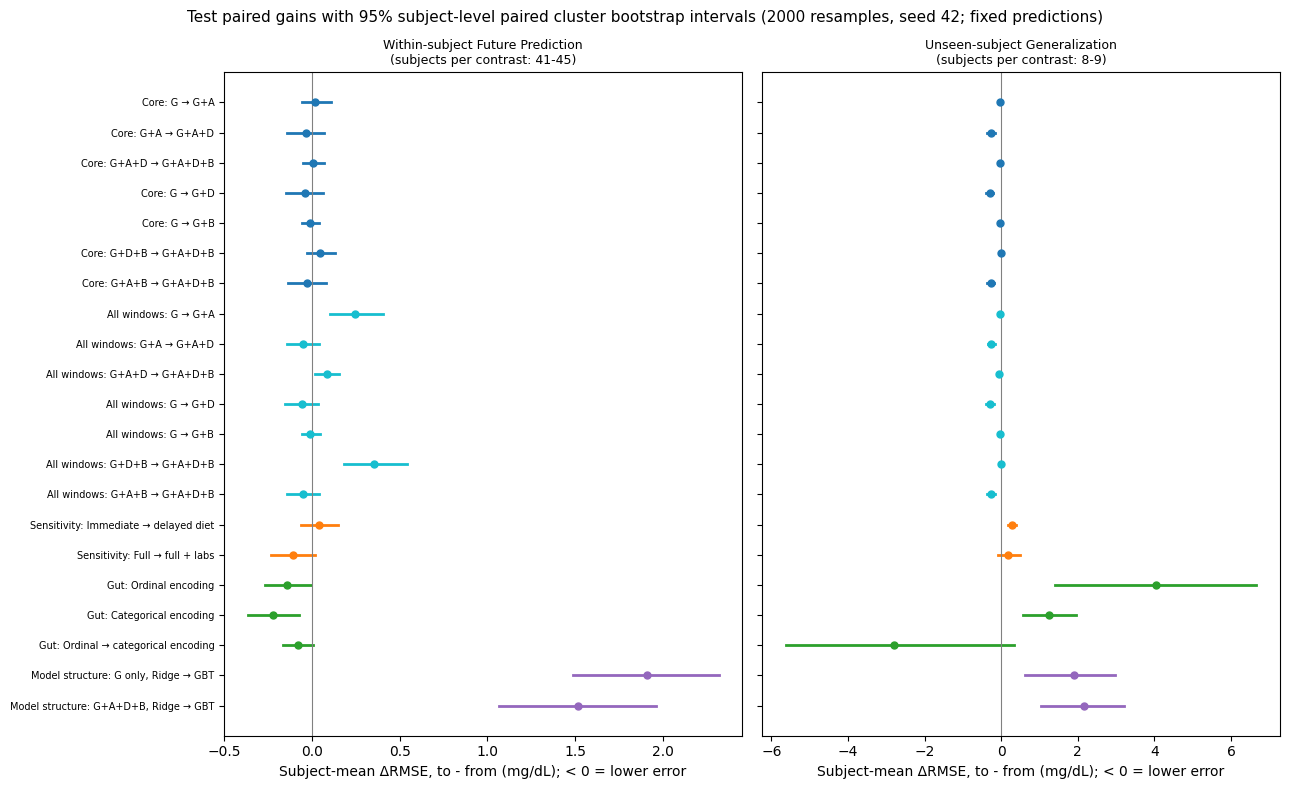

In [16]:
# Uncertainty figure: subject-mean ΔRMSE with its subject-cluster bootstrap interval for every locked contrast.
BLOCK_COLORS = {"core": "tab:blue", "missing_handling_all_windows": "tab:cyan", "sensitivity": "tab:orange",
                "gut_optional": "tab:green", "structure_x_feature_group": "tab:purple"}
BLOCK_LABELS = {"core": "Core", "missing_handling_all_windows": "All windows", "sensitivity": "Sensitivity",
                 "gut_optional": "Gut", "structure_x_feature_group": "Model structure"}
CONTRAST_LABELS = {
    "G->G+A": "G \u2192 G+A", "G+A->G+A+D": "G+A \u2192 G+A+D",
    "G+A+D->G+A+D+B": "G+A+D \u2192 G+A+D+B", "G->G+D": "G \u2192 G+D",
    "G->G+B": "G \u2192 G+B", "G+D+B->G+A+D+B": "G+D+B \u2192 G+A+D+B",
    "G+A+B->G+A+D+B": "G+A+B \u2192 G+A+D+B", "diet_delay": "Immediate \u2192 delayed diet",
    "offline_lab_bio": "Full \u2192 full + labs", "gut_ordinal": "Ordinal encoding",
    "gut_categorical": "Categorical encoding", "gut_encoding": "Ordinal \u2192 categorical encoding",
    "structure_G": "G only, Ridge \u2192 GBT", "structure_G+A+D+B": "G+A+D+B, Ridge \u2192 GBT",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
for ax, protocol in zip(axes, PROTOCOLS):
    part = paired_gain_intervals.loc[paired_gain_intervals["evaluation_protocol"].eq(protocol)].reset_index(drop=True)
    y = np.arange(len(part))[::-1]
    for yi, r in zip(y, part.itertuples()):
        ax.plot([r.d_rmse_ci_low, r.d_rmse_ci_high], [yi, yi], color=BLOCK_COLORS[r.block], linewidth=2)
        ax.scatter([r.d_rmse], [yi], color=BLOCK_COLORS[r.block], zorder=3, s=25)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_yticks(y, [f"{BLOCK_LABELS[r.block]}: {CONTRAST_LABELS[r.contrast_id]}" for r in part.itertuples()], fontsize=7)
    ax.set_title(f"{protocol}\n(subjects per contrast: {part['n_subjects'].min()}-{part['n_subjects'].max()})", fontsize=9)
    ax.set_xlabel("Subject-mean ΔRMSE, to - from (mg/dL); < 0 = lower error")
fig.suptitle(f"Test paired gains with {int(CI_LEVEL * 100)}% subject-level paired cluster bootstrap intervals "
             f"({N_RESAMPLES} resamples, seed {SEED}; fixed predictions)", fontsize=11)
fig.tight_layout()
fig.savefig(EVAL_DIR / "paired_gains.png", dpi=120, metadata={"Software": None})
plt.show()


In [17]:
# Persist paired-gain intervals.
paired_gain_intervals.to_csv(EVAL_DIR / "paired_gain_intervals.csv", index=False)

- All 42 locked contrasts were evaluated on identical subjects and windows: 41 to 45 subjects per contrast for Protocol A and 8 or 9 for Protocol B.
- `paired_gain_intervals.csv` (42 × 42) holds subject-mean $\Delta \mathrm{MAE}$, $\Delta \mathrm{RMSE}$, improved share and pooled-window $\Delta \mathrm{RMSE}$, each with a 95% subject-level paired cluster bootstrap interval (2,000 resamples, seed 42). It also holds subject and window counts, the pre-specified outcome label, the validation label and the contrast metadata.
- Under the pre-specified rule, Protocol A has 3 improved, 14 negligible and 4 worse contrasts; Protocol B has 7 improved, 8 negligible and 6 worse.

# Error Analysis and Factor Interpretation

Errors of the frozen test predictions (as above) are analyzed with rules fixed before any stratified result was viewed. The analysis set is fixed by role: persistence (simple reference), GlucoBench linear regression (formal baseline reproduction), Ridge G (reference), G+D and the full G+A+D+B model on the core cohort, and the all-window full model. Core-cohort models are compared on identical core windows; coverage strata use the all-window models. Strata use fixed bins of target level, realized 30-minute change, time since the last logged meal, a meal logged within the horizon, Libre-Dexcom difference at target, the Libre reporting floor, and cohort or feature availability. Post-origin quantities are used only to describe errors. Extreme errors are the top 1% of absolute error of the core full model per protocol. Trajectories show the subjects with the lowest, median and highest RMSE on their day with the most core windows. Factor interpretation relies only on the locked ablation contrasts from Notebook 05 validation and the Paired Gains and Uncertainty test. No permutation importance or SHAP is used, and no causal claim is made.

In [18]:
# Ablation contrasts evaluated on validation (Notebook 05); the locked test predictions, metrics and paired intervals are in memory.
validation_results = pd.read_csv(ABLATION_DIR / "validation_ablation_results.csv")
validation_results = validation_results.loc[validation_results["record_type"].eq("contrast")]

# Fixed analysis set, chosen by role before looking at any stratified error: simple reference, formal baseline reproduction,
# Ridge G reference, Ridge G+D, Ridge full model on the core cohort, and the all-window full model.
def locked_id(tier, config_id, cohort, family, protocol):
    rows = locked.loc[locked["tier"].eq(tier) & locked["config_id"].eq(config_id) & locked["cohort"].eq(cohort)
                      & locked["family"].eq(family) & locked["evaluation_protocol"].eq(protocol), "experiment_id"]
    assert len(rows) == 1
    return rows.iloc[0]


ANALYSIS_MODELS = {
    "persistence": lambda p: f"baseline|persistence|{p}",
    "glucobench_lr": lambda p: f"baseline|glucobench_linear_regression|{p}",
    "ridge_G_core": lambda p: locked_id("primary", "G", "cohort_core", "ridge", p),
    "ridge_GD_core": lambda p: locked_id("primary", "G+D", "cohort_core", "ridge", p),
    "ridge_full_core": lambda p: locked_id("primary", "G+A+D+B", "cohort_core", "ridge", p),
    "ridge_full_all": lambda p: locked_id("missing_handling_all_windows", "G+A+D+B", "cohort_full", "ridge", p),
}
experiment_of = {(m, p): f(p) for m, f in ANALYSIS_MODELS.items() for p in PROTOCOLS}
assert set(experiment_of.values()) <= set(test_predictions["experiment_id"])
CORE_MODELS = [m for m in ANALYSIS_MODELS if m.endswith("_core")]
ALL_WINDOW_MODELS = [m for m in ANALYSIS_MODELS if not m.endswith("_core")]
print("Analysis set (fixed by role):")
display(pd.DataFrame([{"model": m, "evaluation_protocol": p, "experiment_id": e} for (m, p), e in experiment_of.items()]))


Analysis set (fixed by role):


,model,evaluation_protocol,experiment_id
0,persistence,Within-subject Future Prediction,baseline|persistence|Within-subject Future Pre...
1,persistence,Unseen-subject Generalization,baseline|persistence|Unseen-subject Generaliza...
2,glucobench_lr,Within-subject Future Prediction,baseline|glucobench_linear_regression|Within-s...
3,glucobench_lr,Unseen-subject Generalization,baseline|glucobench_linear_regression|Unseen-s...
4,ridge_G_core,Within-subject Future Prediction,primary|G|cohort_core|ridge|Within-subject Fut...
5,ridge_G_core,Unseen-subject Generalization,primary|G|cohort_core|ridge|Unseen-subject Gen...
6,ridge_GD_core,Within-subject Future Prediction,primary|G+D|cohort_core|ridge|Within-subject F...
7,ridge_GD_core,Unseen-subject Generalization,primary|G+D|cohort_core|ridge|Unseen-subject G...
8,ridge_full_core,Within-subject Future Prediction,primary|G+A+D+B|cohort_core|ridge|Within-subje...
9,ridge_full_core,Unseen-subject Generalization,primary|G+A+D+B|cohort_core|ridge|Unseen-subje...


In [19]:
# One row per admitted test window: frozen predictions of the analysis set plus context from upstream task artifacts.
# Post-origin quantities (next logged meal, realised 30-min change, Dexcom at target) are used only to stratify errors.
wide = (test_predictions.loc[test_predictions["experiment_id"].isin(experiment_of.values())]
        .assign(model=lambda d: d["experiment_id"].map({e: m for (m, p), e in experiment_of.items()}))
        .pivot_table(index=FOLD_KEY + ["target_time", "target_value"], columns="model", values="prediction", aggfunc="first")
        .reset_index())
wide.columns.name = None
wide = wide.merge(cohorts.loc[cohorts["split"].eq("test")].drop(columns="split"), on=FOLD_KEY, how="left", validate="one_to_one")
manifest = pd.read_parquet(PROJECT_ROOT / "artifacts" / "03_eda_task_samples" / "window_manifest.parquet",
                           columns=WINDOW_KEY + ["history_inserted_points", "target_value_origin"])
analysis_samples = samples[WINDOW_KEY + ["glucose_lag_0min", "glucose_slope_30min"]]
wide = (wide.merge(manifest, on=WINDOW_KEY, how="left", validate="many_to_one")
            .merge(analysis_samples, on=WINDOW_KEY, how="left", validate="many_to_one"))

# Logged meal times (02 meal events): minutes since the last meal at or before the origin and to the next meal after it.
meals = pd.read_parquet(PROJECT_ROOT / "artifacts" / "02_clean_align" / "meal_events.parquet", columns=["subject", "timestamp"]).sort_values("timestamp")
wide = wide.sort_values("origin_time")
last_meal = pd.merge_asof(wide[["subject", "origin_time"]], meals.rename(columns={"timestamp": "last_meal_time"}),
                          left_on="origin_time", right_on="last_meal_time", by="subject", direction="backward")
next_meal = pd.merge_asof(wide[["subject", "origin_time"]], meals.rename(columns={"timestamp": "next_meal_time"}),
                          left_on="origin_time", right_on="next_meal_time", by="subject", direction="forward", allow_exact_matches=False)
wide["minutes_since_last_meal"] = ((wide["origin_time"] - last_meal["last_meal_time"].to_numpy()).dt.total_seconds() / 60).to_numpy()
wide["minutes_to_next_meal"] = ((next_meal["next_meal_time"].to_numpy() - wide["origin_time"]).dt.total_seconds() / 60).to_numpy()

# Second CGM device at the target time (02 aligned grid); the task target is always Libre.
dexcom_grid = grid[["subject", "timestamp", "dexcom_gl"]]
wide = wide.merge(dexcom_grid.rename(columns={"timestamp": "target_time", "dexcom_gl": "dexcom_at_target"}), on=["subject", "target_time"],
                  how="left", validate="many_to_one").sort_values(FOLD_KEY).reset_index(drop=True)
wide["device_gap"] = (wide["target_value"] - wide["dexcom_at_target"]).abs()
wide["change_30min"] = wide["target_value"] - wide["glucose_lag_0min"]

# Pre-defined strata (clinical glucose bands and fixed round-number bins).
def bands(values, edges, labels, missing=None):
    out = pd.cut(values, edges, labels=labels, right=False).astype(object)
    return out.where(values.notna(), missing) if missing else out

STRATUM_ORDER = {
    "target_level": ["<70", "70-140", "140-180", "180-250", ">=250"],
    "change_30min_band": ["|change|<10", "10-30", "30-50", ">=50"],
    "time_since_meal": ["0-30", "30-60", "60-120", "120-240", ">=240", "no earlier meal"],
    "device_gap_band": ["<10", "10-20", "20-40", ">=40", "Dexcom missing"],
}
wide["target_level"] = bands(wide["target_value"], [0, 70, 140, 180, 250, np.inf], STRATUM_ORDER["target_level"])
wide["change_30min_band"] = bands(wide["change_30min"].abs(), [0, 10, 30, 50, np.inf], STRATUM_ORDER["change_30min_band"])
wide["time_since_meal"] = bands(wide["minutes_since_last_meal"], [0, 30, 60, 120, 240, np.inf], STRATUM_ORDER["time_since_meal"][:-1], "no earlier meal")
wide["meal_in_horizon"] = np.where(wide["minutes_to_next_meal"] <= HORIZON_MIN, "meal logged in (t, t+30]", "no meal in (t, t+30]")
wide["device_gap_band"] = bands(wide["device_gap"], [0, 10, 20, 40, np.inf], STRATUM_ORDER["device_gap_band"][:-1], "Dexcom missing")
# Libre reports readings below its lower limit at the limit (device specification); such targets are floor-censored.
LIBRE_REPORTING_FLOOR = 40
assert wide["target_value"].min() >= LIBRE_REPORTING_FLOOR
wide["libre_floor"] = np.where(wide["target_value"] <= LIBRE_REPORTING_FLOOR, "target at Libre floor (40)", "target above floor")
wide["history_interpolated"] = np.where(wide["history_inserted_points"] > 0, "history has inserted points", "history fully observed")
wide["core_membership"] = np.where(wide["cohort_core"], "in core cohort", "outside core cohort")
for group in ["A", "D", "B", "Gut"]:
    wide[f"{group}_availability"] = np.where(wide[f"available_{group}"], f"{group} available", f"{group} unavailable")
for m in ANALYSIS_MODELS:
    wide[f"err_{m}"] = wide[m] - wide["target_value"]
print(f"Analysis frame: {wide.shape}; windows per protocol:")
display(wide.groupby("evaluation_protocol").agg(windows=("subject", "size"), subjects=("subject", "nunique"), core_windows=("cohort_core", "sum"),
                                                with_dexcom=("dexcom_at_target", lambda s: int(s.notna().sum()))))

Analysis frame: (54591, 47); windows per protocol:


,windows,subjects,core_windows,with_dexcom
evaluation_protocol,,,,
Unseen-subject Generalization,28322,9,26861,25248
Within-subject Future Prediction,26269,45,21083,16260


In [20]:
# Pooled-window error by stratum. Core-cohort models are compared on identical core windows; coverage strata use the
# all-window models. Stratified values are pooled over windows (not subject-equal) and are labelled as such.
records = []


def add(analysis, protocol, model, stratum_variable, stratum, metric, value, n_windows=np.nan, n_subjects=np.nan, label=None, detail=None):
    records.append({"analysis": analysis, "evaluation_protocol": protocol, "model": model,
                    "experiment_id": experiment_of.get((model, protocol)), "stratum_variable": stratum_variable, "stratum": stratum,
                    "metric": metric, "value": value, "label": label, "n_windows": n_windows, "n_subjects": n_subjects, "detail": detail})


def pooled_rows(analysis, frame, variable, models, paired=()):
    for protocol, g in frame.groupby("evaluation_protocol", sort=False):
        present = set(g[variable])
        for stratum in [s for s in STRATUM_ORDER.get(variable, sorted(present)) if s in present]:
            s = g.loc[g[variable].eq(stratum)]
            n, k = len(s), s["subject"].nunique()
            add(analysis, protocol, None, variable, stratum, "window_share", n / len(g), n, k)
            for m in models:
                e = s[f"err_{m}"]
                add(analysis, protocol, m, variable, stratum, "pooled_window_mae", e.abs().mean(), n, k)
                add(analysis, protocol, m, variable, stratum, "pooled_window_rmse", np.sqrt((e ** 2).mean()), n, k)
                add(analysis, protocol, m, variable, stratum, "bias_mean_error", e.mean(), n, k)
            for to, frm in paired:
                d = np.sqrt((s[f"err_{to}"] ** 2).mean()) - np.sqrt((s[f"err_{frm}"] ** 2).mean())
                add(analysis, protocol, to, variable, stratum, "pooled_window_d_rmse", d, n, k, label=f"{to} - {frm}",
                    detail=f"minus {experiment_of[(frm, protocol)]}")


core = wide.loc[wide["cohort_core"]].copy()
all_models = CORE_MODELS + ALL_WINDOW_MODELS
PAIRS = [("ridge_full_core", "ridge_G_core"), ("ridge_GD_core", "ridge_G_core")]
pooled_rows("overall_core_windows", core.assign(all="all core windows"), "all", all_models, PAIRS)
for variable in ["target_level", "change_30min_band", "time_since_meal", "meal_in_horizon", "device_gap_band", "libre_floor"]:
    pooled_rows(variable, core, variable, all_models, PAIRS)
pooled_rows("overall_all_windows", wide.assign(all="all test windows"), "all", ALL_WINDOW_MODELS)
for variable in ["core_membership", "A_availability", "D_availability", "B_availability", "Gut_availability", "history_interpolated", "libre_floor"]:
    pooled_rows("coverage", wide, variable, ALL_WINDOW_MODELS)
strata = pd.DataFrame(records)

view = strata.loc[strata["metric"].eq("pooled_window_rmse") & strata["analysis"].isin(["target_level", "change_30min_band", "time_since_meal", "meal_in_horizon", "device_gap_band", "libre_floor"])]
for protocol in PROTOCOLS:
    print(f"\n{protocol}: pooled-window RMSE (mg/dL) on identical core windows")
    table = view.loc[view["evaluation_protocol"].eq(protocol)].pivot_table(index=["analysis", "stratum"], columns="model", values="value", sort=False)
    shares = strata.loc[strata["metric"].eq("window_share") & strata["evaluation_protocol"].eq(protocol)]
    delta = strata.loc[strata["metric"].eq("pooled_window_d_rmse") & strata["evaluation_protocol"].eq(protocol)].pivot_table(
        index=["analysis", "stratum"], columns="label", values="value", sort=False)
    display(table[all_models].join(delta).join(shares.set_index(["analysis", "stratum"])[["n_windows", "n_subjects"]]).round(2))
    coverage = strata.loc[strata["analysis"].eq("coverage") & strata["metric"].eq("pooled_window_rmse") & strata["evaluation_protocol"].eq(protocol)]
    print(f"{protocol}: coverage strata, pooled-window RMSE on all test windows")
    display(coverage.pivot_table(index=["stratum_variable", "stratum"], columns="model", values="value", sort=False)[ALL_WINDOW_MODELS]
            .join(shares.loc[shares["analysis"].eq("coverage")].set_index(["stratum_variable", "stratum"])[["n_windows", "n_subjects"]]).round(2))



Within-subject Future Prediction: pooled-window RMSE (mg/dL) on identical core windows


ridge_G_core  ridge_GD_core  ridge_full_core  persistence  glucobench_lr  ridge_full_all  \
analysis          stratum                                                                                                                
target_level      <70                                 8.12           8.01             8.34         8.02           8.28            8.34   
                  70-140                              9.96           9.93             9.91        12.66           9.55            9.91   
                  140-180                            14.54          14.34            14.23        22.11          14.15           14.23   
                  180-250                            19.01          19.12            19.22        30.27          18.64           19.22   
                  >=250                              22.39          22.58            23.30        33.30          21.48           23.30   
change_30min_band |change|<10                         6.71           6.73             6.85         4.65           6.49            6.85   
                  10-30                              12.72          12.77            12.74        17.83          12.30           12.74   
                  30-50                              23.65          23.31            23.02        37.86          22.71           23.02   
                  >=50                               38.79          38.44            38.49        62.99          37.83           38.49   
time_since_meal   0-30                               18.20          17.48            17.37        27.36          17.55           17.37   
                  30-60                              15.16          15.34            15.31        22.05          14.59           15.31   
                  60-120                             11.91          12.00            12.00        17.95          11.53           12.00   
                  120-240                            10.62          10.50            10.45        14.18          10.27           10.45   
                  >=240                              10.29          10.34            10.40        13.45           9.97           10.40   
meal_in_horizon   meal logged in (t, t+30]           15.57          15.85            15.71        18.95          15.46           15.71   
                  no meal in (t, t+30]               11.14          11.07            11.10        15.57          10.74           11.10   
device_gap_band   <10                                15.20          14.72            14.71        20.02          14.86           14.71   
                  10-20                              10.75          10.70            10.79        15.00          10.41           10.79   
                  20-40                               9.89           9.81             9.78        13.27           9.56            9.78   
                  >=40                               10.84          10.83            10.78        14.67          10.56           10.78   
                  Dexcom missing                     12.91          13.02            13.09        18.59          12.38           13.09   
libre_floor       target above floor                 11.52          11.49            11.49        15.92          11.14           11.49   
                  target at Libre floor (40)          5.17           4.83             5.69         3.45           5.14            5.69   

                                              ridge_full_core - ridge_G_core  ridge_GD_core - ridge_G_core  n_windows  n_subjects  
analysis          stratum                                                                                                          
target_level      <70                                                   0.22                         -0.11       1402          18  
                  70-140                                               -0.05                         -0.03      15610          42  
                  140-180                                          

Within-subject Future Prediction: coverage strata, pooled-window RMSE on all test windows


persistence  glucobench_lr  ridge_full_all  n_windows  n_subjects
stratum_variable     stratum                                                                                      
core_membership      in core cohort                    15.79          11.06           11.41      21083          44
                     outside core cohort               14.61          10.30           12.43       5186          20
A_availability       A available                       15.79          11.06           11.41      21083          44
                     A unavailable                     14.61          10.30           12.43       5186          20
D_availability       D available                       15.56          10.92           11.62      26269          45
B_availability       B available                       15.56          10.92           11.62      26269          45
Gut_availability     Gut available                     15.63          10.91           11.55      24264          42
                     Gut unavailable                   14.79          11.06           12.45       2005           3
history_interpolated history fully observed            15.56          10.92           11.62      26269          45
libre_floor          target above floor                15.76          11.02           11.74      25601          45
                     target at Libre floor (40)         2.97           6.15            5.40        668           4


Unseen-subject Generalization: pooled-window RMSE (mg/dL) on identical core windows


ridge_G_core  ridge_GD_core  ridge_full_core  persistence  glucobench_lr  ridge_full_all  \
analysis          stratum                                                                                                                
target_level      <70                                 8.85           8.64             8.47         8.31           9.82            8.48   
                  70-140                             10.18          10.00             9.95        13.21           9.97            9.95   
                  140-180                            18.20          17.56            17.53        27.69          17.71           17.52   
                  180-250                            22.76          21.78            21.85        36.19          21.60           21.87   
                  >=250                              25.45          25.42            26.17        42.42          23.09           26.31   
change_30min_band |change|<10                         6.67           6.58             6.51         4.56           6.79            6.51   
                  10-30                              13.10          12.99            12.91        17.89          12.97           12.91   
                  30-50                              23.76          22.84            22.82        37.78          23.15           22.83   
                  >=50                               39.62          37.60            37.64        63.25          38.36           37.67   
time_since_meal   0-30                               20.69          18.72            18.68        30.30          19.82           18.68   
                  30-60                              16.36          16.40            16.29        21.98          16.29           16.28   
                  60-120                             12.05          12.08            12.07        17.35          12.85           12.07   
                  120-240                             9.90           9.78             9.74        13.98           9.52            9.74   
                  >=240                               8.79           8.75             8.70        10.37           8.64            8.70   
                  no earlier meal                     9.30           9.08             8.88         8.32           9.09            8.88   
meal_in_horizon   meal logged in (t, t+30]           16.26          16.47            16.46        19.64          16.07           16.47   
                  no meal in (t, t+30]               11.03          10.67            10.62        15.27          10.90           10.62   
device_gap_band   <10                                11.68          11.44            11.46        15.59          11.39           11.46   
                  10-20                              11.87          11.53            11.55        16.52          11.50           11.54   
                  20-40                              10.42          10.20            10.16        14.80          10.09           10.16   
                  >=40                               12.39          11.98            11.86        16.17          12.58           11.86   
                  Dexcom missing                     11.35          11.40            11.38        15.57          11.02           11.38   
libre_floor       target above floor                 11.67          11.38            11.33        16.00          11.49           11.33   
                  target at Libre floor (40)          7.69           7.47             7.30         4.44           8.81            7.31   

                                              ridge_full_core - ridge_G_core  ridge_GD_core - ridge_G_core  n_windows  n_subjects  
analysis          stratum                                                                                                          
target_level      <70                                                  -0.39                         -0.21       4751           8  
                  70-140                                     

Unseen-subject Generalization: coverage strata, pooled-window RMSE on all test windows


persistence  glucobench_lr  ridge_full_all  n_windows  n_subjects
stratum_variable     stratum                                                                                      
core_membership      in core cohort                    15.65          11.38           11.17      26861           9
                     outside core cohort               12.69           8.97            9.12       1461           5
A_availability       A available                       15.65          11.38           11.17      26861           9
                     A unavailable                     12.69           8.97            9.12       1461           5
D_availability       D available                       15.51          11.27           11.08      28322           9
B_availability       B available                       15.51          11.27           11.08      28322           9
Gut_availability     Gut available                     15.84          11.25           11.01      24916           8
                     Gut unavailable                   12.85          11.38           11.59       3406           1
history_interpolated history fully observed            15.51          11.27           11.08      28322           9
libre_floor          target above floor                15.89          11.40           11.25      26860           9
                     target at Libre floor (40)         4.22           8.50            7.12       1462           4

The comparison of GlucoBench LR and Ridge on identical core windows below is descriptive and not a locked contrast.


In [21]:
# Subject differences: per-subject RMSE from the Subject-Level Metrics table above, related to each subject's test glucose level and variability.
subject_context = core.groupby(["evaluation_protocol", "subject"]).agg(target_mean=("target_value", "mean"), target_sd=("target_value", "std"),
                                                                      share_ge_180=("target_value", lambda v: (v >= 180).mean()))
for protocol in PROTOCOLS:
    per_subject = (metrics_by_subject.loc[metrics_by_subject["experiment_id"].eq(experiment_of[("ridge_full_core", protocol)])]
                   .set_index("subject")[["n_windows", "mae", "rmse"]]
                   .join(metrics_by_subject.loc[metrics_by_subject["experiment_id"].eq(experiment_of[("persistence", protocol)])]
                         .set_index("subject")["rmse"].rename("rmse_persistence"))
                   .join(subject_context.loc[protocol]))
    for s, r in per_subject.iterrows():
        add("subject", protocol, "ridge_full_core", "subject", str(s), "rmse", r["rmse"], r["n_windows"], 1,
            detail=json.dumps({"mae": round(r["mae"], 4), "rmse_persistence": round(r["rmse_persistence"], 4), "target_mean": round(r["target_mean"], 2),
                               "target_sd": round(r["target_sd"], 2), "share_target_ge_180": round(r["share_ge_180"], 4)}))
    for col in ["target_sd", "target_mean", "rmse_persistence"]:
        add("subject", protocol, "ridge_full_core", "subject", "all subjects", f"spearman_rmse_vs_{col}",
            per_subject["rmse"].corr(per_subject[col], method="spearman"), per_subject["n_windows"].sum(), len(per_subject))
    q = per_subject["rmse"].quantile([0, 0.25, 0.5, 0.75, 1]).to_dict()
    for name, v in zip(["min", "q25", "median", "q75", "max"], q.values()):
        add("subject", protocol, "ridge_full_core", "subject", "all subjects", f"subject_rmse_{name}", v, per_subject["n_windows"].sum(), len(per_subject))
    print(f"\n{protocol}: per-subject RMSE of ridge_full_core (Subject-Level Metrics section), highest five and spread")
    display(per_subject.sort_values("rmse", ascending=False).head(5).round(2))
    print(f"Subject RMSE range {q[0]:.2f}-{q[1]:.2f} mg/dL; Spearman with target SD "
          f"{per_subject['rmse'].corr(per_subject['target_sd'], method='spearman'):.2f}, with persistence RMSE "
          f"{per_subject['rmse'].corr(per_subject['rmse_persistence'], method='spearman'):.2f}")



Within-subject Future Prediction: per-subject RMSE of ridge_full_core (Subject-Level Metrics section), highest five and spread


,n_windows,mae,rmse,rmse_persistence,target_mean,target_sd,share_ge_180
subject,,,,,,,
7,40,7.30,18.85,18.44,46.10,17.62,0.00
30,292,11.22,16.61,20.09,163.24,67.12,0.29
35,546,11.65,16.08,20.87,227.72,44.58,0.86
49,582,11.20,15.69,24.09,145.90,49.74,0.26
45,437,9.75,15.39,22.22,131.34,42.12,0.10


Subject RMSE range 5.51-18.85 mg/dL; Spearman with target SD 0.58, with persistence RMSE 0.78

Unseen-subject Generalization: per-subject RMSE of ridge_full_core (Subject-Level Metrics section), highest five and spread


,n_windows,mae,rmse,rmse_persistence,target_mean,target_sd,share_ge_180
subject,,,,,,,
3,2851,7.91,12.86,21.10,107.41,30.17,0.04
36,3049,8.45,12.50,17.72,109.89,42.68,0.08
48,3406,7.94,11.60,12.85,82.79,20.40,0.00
15,2829,7.05,11.52,9.31,52.01,14.99,0.00
13,3064,7.09,10.59,15.16,125.69,23.30,0.03


Subject RMSE range 10.20-12.86 mg/dL; Spearman with target SD 0.13, with persistence RMSE 0.32


The lowest and highest subject RMSE in Protocol A are both affected by readings at the Libre floor.


In [22]:
# Extreme errors (pre-defined): the top 1% of |error| of ridge_full_core per protocol on core windows. Their context is compared
# with all core windows, and the ten largest per protocol are listed with their keys for case tracing.
EXTREME_QUANTILE = 0.99
N_CASES = 10
# Physiologically implausible predictions (outside the CGM reporting range) for every analysis model on its own coverage.
for protocol, g in wide.groupby("evaluation_protocol", sort=False):
    for m in ANALYSIS_MODELS:
        v = g[m].dropna()
        for name, mask in [("prediction < 0", v < 0), ("prediction < 40", v < 40), ("prediction > 400", v > 400)]:
            add("implausible_predictions", protocol, m, "prediction_range", name, "count", int(mask.sum()), len(v),
                int(g.loc[mask[mask].index, "subject"].nunique()))
        if m in ALL_WINDOW_MODELS:
            outside = (v < 40) & ~g.loc[v.index, "cohort_core"]
            add("implausible_predictions", protocol, m, "prediction_range", "prediction < 40, outside core cohort", "count", int(outside.sum()),
                int((~g.loc[v.index, "cohort_core"]).sum()), int(g.loc[outside[outside].index, "subject"].nunique()))
# Floor-censored Libre targets by subject (all test windows).
for protocol, g in wide.groupby("evaluation_protocol", sort=False):
    per_subject_floor = g.groupby("subject")["target_value"].agg(windows="size", at_floor=lambda v: int((v <= LIBRE_REPORTING_FLOOR).sum()))
    for subject, r in per_subject_floor.loc[per_subject_floor["at_floor"] > 0].iterrows():
        add("libre_floor", protocol, None, "subject", str(subject), "share_target_at_floor", r["at_floor"] / r["windows"], r["windows"], 1,
            detail=json.dumps({"windows_at_floor": int(r["at_floor"])}))
    print(f"{protocol}: {int(per_subject_floor['at_floor'].sum())} test targets at the Libre floor, from "
          f"{int((per_subject_floor['at_floor'] > 0).sum())} subjects; largest subject share "
          f"{(per_subject_floor['at_floor'] / per_subject_floor['windows']).max():.1%}")
implausible = pd.DataFrame([r for r in records if r["analysis"] == "implausible_predictions"])
print("Predictions outside the CGM reporting range (count of windows; subjects affected in brackets):")
display(implausible.assign(cell=lambda d: d["value"].astype(int).astype(str) + " (" + d["n_subjects"].astype(int).astype(str) + ")")
        .pivot_table(index=["evaluation_protocol", "model"], columns="stratum", values="cell", aggfunc="first", sort=False))
for protocol, g in core.groupby("evaluation_protocol", sort=False):
    abs_err = g["err_ridge_full_core"].abs()
    threshold = abs_err.quantile(EXTREME_QUANTILE)
    extreme = g.loc[abs_err >= threshold]
    add("extreme_errors", protocol, "ridge_full_core", "extreme", f"top {100 * (1 - EXTREME_QUANTILE):.0f}% |error|", "abs_error_threshold",
        threshold, len(extreme), extreme["subject"].nunique())
    persistence_threshold = g["err_persistence"].abs().quantile(EXTREME_QUANTILE)
    features = {
        "underprediction (error < 0)": lambda d: d["err_ridge_full_core"] < 0,
        "target < 70": lambda d: d["target_value"] < 70,
        "target >= 180": lambda d: d["target_value"] >= 180,
        "|30-min change| >= 50": lambda d: d["change_30min"].abs() >= 50,
        "meal logged in (t, t+30]": lambda d: d["minutes_to_next_meal"] <= HORIZON_MIN,
        "last meal within 60 min": lambda d: d["minutes_since_last_meal"] < 60,
        "Libre-Dexcom gap >= 20 at target": lambda d: d["device_gap"] >= 20,
        "history has inserted points": lambda d: d["history_inserted_points"] > 0,
        "persistence error also in its top 1%": lambda d: d["err_persistence"].abs() >= persistence_threshold,
    }
    for name, rule in features.items():
        add("extreme_errors", protocol, "ridge_full_core", "extreme_share", name, "share_in_extreme", rule(extreme).mean(), len(extreme), extreme["subject"].nunique())
        add("extreme_errors", protocol, "ridge_full_core", "extreme_share", name, "share_in_all_core", rule(g).mean(), len(g), g["subject"].nunique())
    top_subject_share = extreme["subject"].value_counts(normalize=True)
    add("extreme_errors", protocol, "ridge_full_core", "extreme_share", "largest single-subject share", "share_in_extreme",
        top_subject_share.iloc[0], len(extreme), extreme["subject"].nunique(), label=f"subject {top_subject_share.index[0]}")
    add("extreme_errors", protocol, "ridge_full_core", "extreme_share", "largest single-subject share", "share_in_all_core",
        (g["subject"] == top_subject_share.index[0]).mean(), len(g), g["subject"].nunique(), label=f"subject {top_subject_share.index[0]}")
    cases = g.assign(abs_error=abs_err).nlargest(N_CASES, "abs_error")
    for rank, r in enumerate(cases.itertuples(), start=1):
        add("extreme_case", protocol, "ridge_full_core", "rank", str(rank), "abs_error", r.abs_error, 1, 1, detail=json.dumps({
            "subject": int(r.subject), "origin_time": str(r.origin_time), "target_time": str(r.target_time), "task_id": r.task_id,
            "target": round(r.target_value, 2), "prediction": round(r.ridge_full_core, 2), "ridge_G_core": round(r.ridge_G_core, 2),
            "ridge_GD_core": round(r.ridge_GD_core, 2), "glucobench_lr": round(r.glucobench_lr, 2), "persistence": round(r.persistence, 2),
            "slope_30min_at_origin": round(r.glucose_slope_30min, 4),
            "value_at_origin": round(r.glucose_lag_0min, 2), "dexcom_at_target": None if pd.isna(r.dexcom_at_target) else round(r.dexcom_at_target, 2),
            "minutes_since_last_meal": None if pd.isna(r.minutes_since_last_meal) else round(r.minutes_since_last_meal, 1),
            "minutes_to_next_meal": None if pd.isna(r.minutes_to_next_meal) else round(r.minutes_to_next_meal, 1),
            "history_inserted_points": int(r.history_inserted_points), "target_value_origin": r.target_value_origin}))
    print(f"\n{protocol}: |error| threshold {threshold:.1f} mg/dL; {len(extreme)} extreme windows from {extreme['subject'].nunique()} subjects")
    shares = pd.DataFrame([r for r in records if r["analysis"] == "extreme_errors" and r["evaluation_protocol"] == protocol and r["stratum_variable"] == "extreme_share"])
    display(shares.assign(label=shares["label"].fillna("")).pivot_table(index=["stratum", "label"], columns="metric", values="value", sort=False).round(3))
    display(cases[["subject", "origin_time", "target_value", "ridge_full_core", "ridge_G_core", "ridge_GD_core", "glucobench_lr", "persistence",
                   "glucose_slope_30min", "dexcom_at_target", "minutes_since_last_meal", "minutes_to_next_meal"]].round(1).reset_index(drop=True))


Unseen-subject Generalization: 1462 test targets at the Libre floor, from 4 subjects; largest subject share 40.9%
Within-subject Future Prediction: 668 test targets at the Libre floor, from 4 subjects; largest subject share 85.0%
Predictions outside the CGM reporting range (count of windows; subjects affected in brackets):


stratum                                          prediction < 0 prediction < 40 prediction > 400 prediction < 40, outside core cohort
evaluation_protocol              model                                                                                               
Unseen-subject Generalization    persistence              0 (0)           0 (0)            0 (0)                                0 (0)
                                 glucobench_lr           11 (1)         186 (4)            0 (0)                               20 (1)
                                 ridge_G_core             4 (1)         143 (4)            0 (0)                                  NaN
                                 ridge_GD_core            4 (1)         147 (4)            0 (0)                                  NaN
                                 ridge_full_core          4 (1)         185 (4)            0 (0)                                  NaN
                                 ridge_full_all           4 (1)         200 (4)            0 (0)                               17 (1)
Within-subject Future Prediction persistence              0 (0)           0 (0)            0 (0)                                0 (0)
                                 glucobench_lr            0 (0)          65 (3)            0 (0)                               29 (2)
                                 ridge_G_core             0 (0)          27 (3)            0 (0)                                  NaN
                                 ridge_GD_core            0 (0)          25 (4)            0 (0)                                  NaN
                                 ridge_full_core          0 (0)          63 (5)            0 (0)                                  NaN
                                 ridge_full_all           0 (0)         355 (5)            0 (0)                              292 (3)


Unseen-subject Generalization: |error| threshold 39.9 mg/dL; 269 extreme windows from 9 subjects


,metric,share_in_extreme,share_in_all_core
stratum,label,,
underprediction (error < 0),,0.669,0.446
target < 70,,0.074,0.177
target >= 180,,0.264,0.033
|30-min change| >= 50,,0.539,0.017
"meal logged in (t, t+30]",,0.271,0.077
last meal within 60 min,,0.550,0.150
Libre-Dexcom gap >= 20 at target,,0.684,0.687
history has inserted points,,0.000,0.000
persistence error also in its top 1%,,0.424,0.010


,subject,origin_time,target_value,ridge_full_core,ridge_G_core,ridge_GD_core,glucobench_lr,persistence,glucose_slope_30min,dexcom_at_target,minutes_since_last_meal,minutes_to_next_meal
0,15,2024-02-03 13:42:00,70.0,201.2,206.2,202.1,208.4,129.0,3.0,176.4,62.0,232.0
1,15,2024-02-03 13:52:00,70.0,-51.8,-56.4,-53.2,-55.0,96.3,2.3,165.6,72.0,222.0
2,15,2024-02-03 13:37:00,73.3,193.7,197.9,194.6,197.9,105.3,2.0,179.8,57.0,237.0
3,15,2024-02-03 13:57:00,70.0,-35.5,-39.3,-36.5,-71.9,80.0,0.7,163.2,77.0,217.0
4,15,2024-02-02 11:27:00,68.0,172.4,174.3,173.1,177.7,108.0,2.3,164.8,56.0,84.0
5,15,2024-02-02 11:22:00,78.3,167.4,168.5,168.1,168.7,89.0,1.5,168.8,51.0,89.0
6,15,2024-02-03 13:32:00,76.7,163.4,165.7,164.1,188.1,81.7,1.2,189.6,52.0,242.0
7,15,2024-02-03 14:07:00,69.3,151.3,155.9,152.4,183.2,73.3,-1.9,162.8,87.0,207.0
8,13,2024-01-28 11:42:00,170.0,91.1,91.4,91.0,94.9,94.0,-0.4,103.4,239.0,3.0
9,15,2024-02-01 09:12:00,40.0,116.0,112.9,112.7,113.3,78.0,1.3,93.6,37.0,161.0



Within-subject Future Prediction: |error| threshold 40.4 mg/dL; 211 extreme windows from 34 subjects


,metric,share_in_extreme,share_in_all_core
stratum,label,,
underprediction (error < 0),,0.791,0.478
target < 70,,0.024,0.066
target >= 180,,0.379,0.068
|30-min change| >= 50,,0.607,0.018
"meal logged in (t, t+30]",,0.152,0.058
last meal within 60 min,,0.303,0.113
Libre-Dexcom gap >= 20 at target,,0.441,0.564
history has inserted points,,0.000,0.000
persistence error also in its top 1%,,0.469,0.010


,subject,origin_time,target_value,ridge_full_core,ridge_G_core,ridge_GD_core,glucobench_lr,persistence,glucose_slope_30min,dexcom_at_target,minutes_since_last_meal,minutes_to_next_meal
0,45,2025-04-04 10:14:00,231.0,132.2,134.2,132.8,128.5,127.0,0.5,NaN,779.0,10.0
1,7,2023-11-10 05:56:00,120.0,38.9,44.7,44.2,44.2,40.0,0.0,111.0,686.0,388.0
2,45,2025-04-04 10:09:00,209.0,129.3,131.4,130.1,128.0,123.7,0.4,NaN,774.0,15.0
3,2,2019-11-25 12:12:00,141.0,65.9,67.9,65.9,74.8,54.0,0.0,NaN,1074.0,491.0
4,3,2020-03-20 08:48:00,113.0,185.8,185.3,185.0,182.0,182.0,1.8,138.0,35.0,237.0
5,32,2022-01-10 15:54:00,104.0,32.1,27.4,27.6,13.8,45.0,-0.5,171.6,143.0,221.0
6,23,2021-05-14 19:07:00,86.0,156.7,144.5,156.2,142.4,146.0,1.5,131.2,30.0,236.0
7,30,2021-02-01 21:12:00,212.0,141.3,142.1,141.2,142.7,124.0,0.5,294.2,67.0,704.0
8,12,2023-03-06 19:58:00,224.0,154.0,155.9,154.8,155.5,134.0,0.9,140.4,36.0,86.0
9,45,2025-04-04 10:19:00,247.7,179.1,183.7,180.0,200.9,139.7,0.7,NaN,784.0,5.0


Floor-censored targets and out-of-range predictions are listed below.


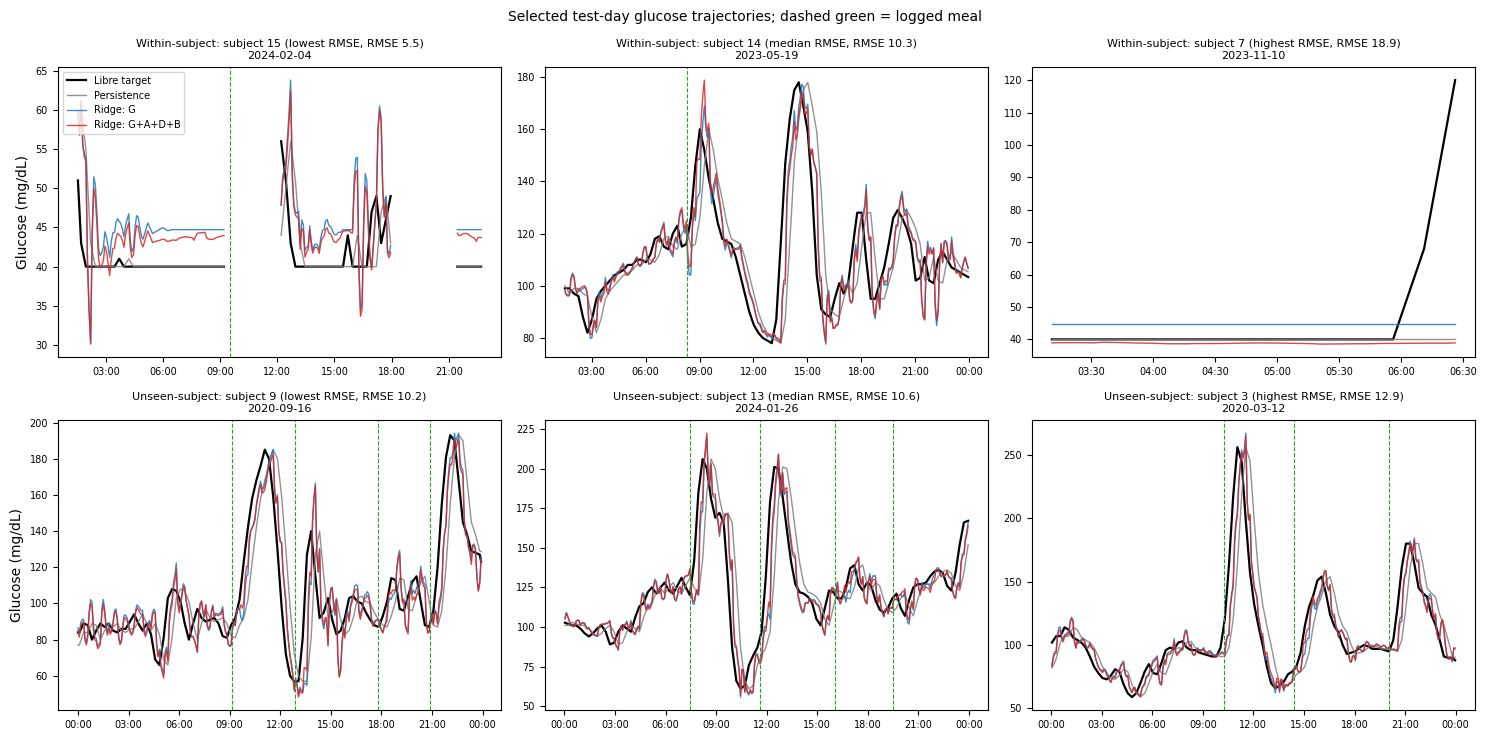

,evaluation_protocol,role,subject,day,subject_rmse
0,Within-subject Future Prediction,lowest RMSE,15,2024-02-04,5.509494
1,Within-subject Future Prediction,median RMSE,14,2023-05-19,10.313971
2,Within-subject Future Prediction,highest RMSE,7,2023-11-10,18.852793
3,Unseen-subject Generalization,lowest RMSE,9,2020-09-16,10.198780
4,Unseen-subject Generalization,median RMSE,13,2024-01-26,10.586385
5,Unseen-subject Generalization,highest RMSE,3,2020-03-12,12.858966


In [23]:
# Pre-defined trajectory rule: per protocol, the subjects with the lowest, median and highest ridge_full_core RMSE (Subject-Level Metrics section);
# for each, the calendar day with the most core test windows (earliest on ties). Logged meals are marked.
DISPLAY_MODEL_LABELS = {"persistence": "Persistence", "ridge_G_core": "Ridge: G", "ridge_full_core": "Ridge: G+A+D+B"}
selected = []
for protocol in PROTOCOLS:
    ranked = (metrics_by_subject.loc[metrics_by_subject["experiment_id"].eq(experiment_of[("ridge_full_core", protocol)])]
              .sort_values(["rmse", "subject"]).reset_index(drop=True))
    for role, idx in [("lowest RMSE", 0), ("median RMSE", (len(ranked) - 1) // 2), ("highest RMSE", len(ranked) - 1)]:
        s = int(ranked.at[idx, "subject"])
        days = core.loc[core["evaluation_protocol"].eq(protocol) & core["subject"].eq(s), "target_time"].dt.normalize().value_counts()
        day = days[days.eq(days.max())].index.min()
        selected.append({"evaluation_protocol": protocol, "role": role, "subject": s, "day": day, "subject_rmse": ranked.at[idx, "rmse"]})
selected = pd.DataFrame(selected)
fig, axes = plt.subplots(len(PROTOCOLS), 3, figsize=(15, 7.5), squeeze=False)
for ax, r in zip(axes.ravel(), selected.itertuples()):
    part = core.loc[core["evaluation_protocol"].eq(r.evaluation_protocol) & core["subject"].eq(r.subject)
                    & core["target_time"].dt.normalize().eq(r.day)].sort_values("target_time")
    # Break lines where consecutive windows are more than one stride apart, so gaps are not drawn as data.
    gaps = part.loc[part["target_time"].diff() > pd.Timedelta(minutes=5), ["target_time"]] - pd.Timedelta(minutes=1)
    part = pd.concat([part, gaps]).sort_values("target_time")
    ax.plot(part["target_time"], part["target_value"], color="black", linewidth=1.6, label="Libre target")
    for m, color in [("persistence", "tab:grey"), ("ridge_G_core", "tab:blue"), ("ridge_full_core", "tab:red")]:
        ax.plot(part["target_time"], part[m], color=color, linewidth=1, alpha=0.85, label=DISPLAY_MODEL_LABELS[m])
    for t in meals.loc[meals["subject"].eq(r.subject) & meals["timestamp"].between(part["target_time"].min(), part["target_time"].max()), "timestamp"]:
        ax.axvline(t, color="tab:green", linestyle="--", linewidth=0.8)
    ax.set_title(f"{r.evaluation_protocol.split()[0]}: subject {r.subject} ({r.role}, RMSE {r.subject_rmse:.1f})\n{r.day.date()}", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_formatter(DateFormatter("%H:%M"))
axes[0, 0].set_ylabel("Glucose (mg/dL)")
axes[1, 0].set_ylabel("Glucose (mg/dL)")
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Selected test-day glucose trajectories; dashed green = logged meal", fontsize=10)
fig.tight_layout()
fig.savefig(EVAL_DIR / "test_trajectories.png", dpi=110, metadata={"Software": None})
plt.show()

for r in selected.itertuples():
    add("trajectory_selection", r.evaluation_protocol, "ridge_full_core", "subject", str(r.subject), "rmse", r.subject_rmse, label=r.role, detail=str(r.day.date()))
display(selected)


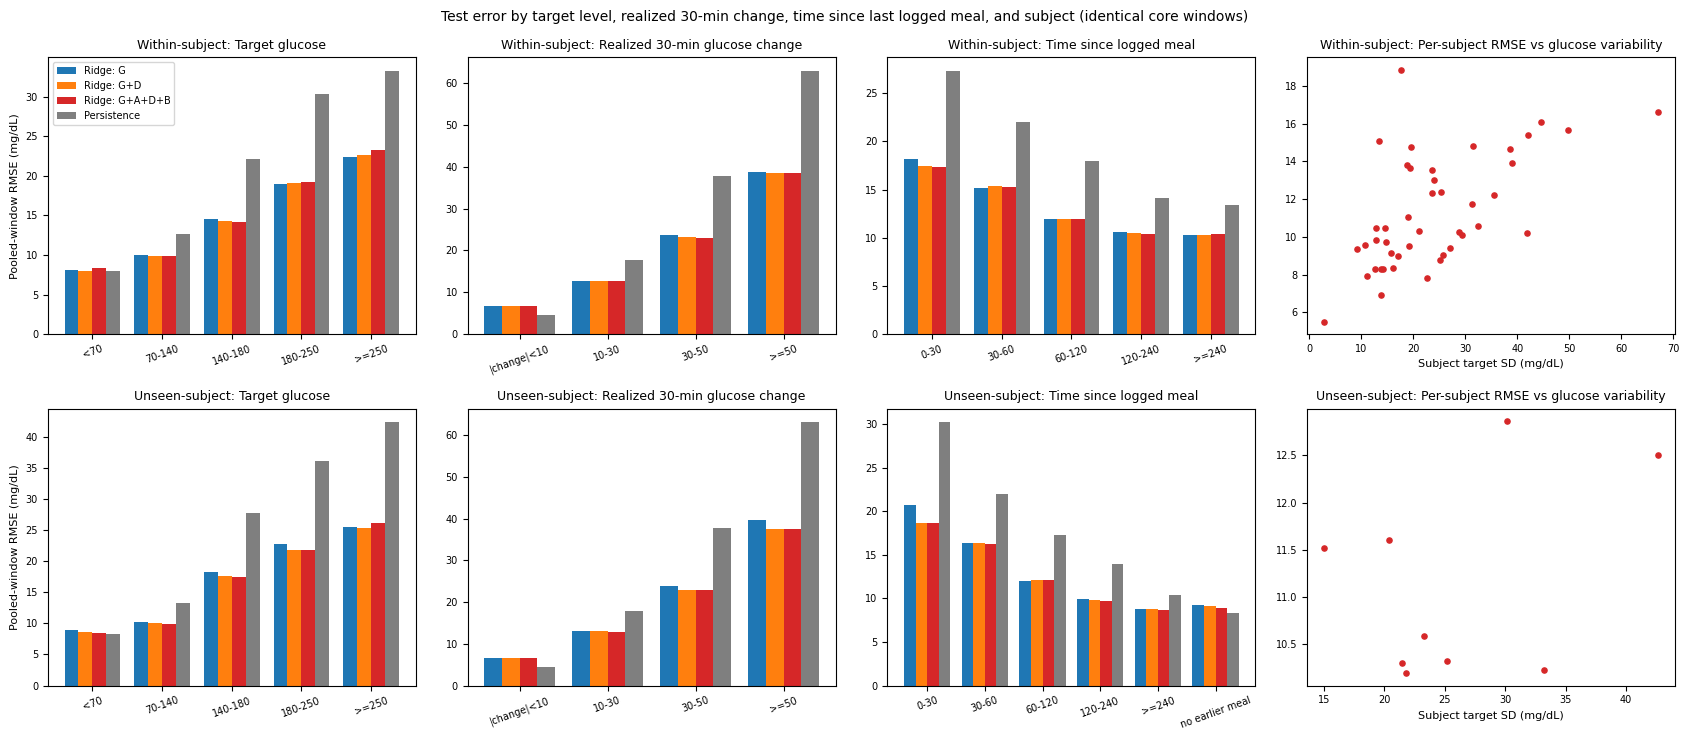

In [24]:
# Error figure: pooled-window RMSE by target level, realised 30-min change and time since the last logged meal (core windows),
# and per-subject RMSE against the subject's target variability.
fig, axes = plt.subplots(len(PROTOCOLS), 4, figsize=(17, 7.5), squeeze=False)
colors = {"persistence": "tab:grey", "glucobench_lr": "tab:olive", "ridge_G_core": "tab:blue", "ridge_GD_core": "tab:orange",
          "ridge_full_core": "tab:red", "ridge_full_all": "tab:pink"}
VARIABLE_LABELS = {"target_level": "Target glucose", "change_30min_band": "Realized 30-min glucose change",
                   "time_since_meal": "Time since logged meal"}
MODEL_LABELS = {"persistence": "Persistence", "glucobench_lr": "GlucoBench LR", "ridge_G_core": "Ridge: G",
                "ridge_GD_core": "Ridge: G+D", "ridge_full_core": "Ridge: G+A+D+B",
                "ridge_full_all": "Ridge: G+A+D+B (all windows)"}
for row, protocol in enumerate(PROTOCOLS):
    for col, variable in enumerate(["target_level", "change_30min_band", "time_since_meal"]):
        ax = axes[row, col]
        part = strata.loc[strata["analysis"].eq(variable) & strata["metric"].eq("pooled_window_rmse") & strata["evaluation_protocol"].eq(protocol)]
        order = [s for s in STRATUM_ORDER[variable] if s in set(part["stratum"])]
        for i, m in enumerate(CORE_MODELS + ["persistence"]):
            vals = part.loc[part["model"].eq(m)].set_index("stratum").reindex(order)["value"]
            ax.bar(np.arange(len(order)) + (i - 1.5) * 0.2, vals, width=0.2, color=colors[m], label=MODEL_LABELS[m])
        ax.set_xticks(range(len(order)), order, fontsize=7, rotation=20)
        ax.set_title(f"{protocol.split()[0]}: {VARIABLE_LABELS[variable]}", fontsize=9)
        ax.tick_params(axis="y", labelsize=7)
    ax = axes[row, 3]
    subj = pd.DataFrame([r for r in records if r["analysis"] == "subject" and r["evaluation_protocol"] == protocol and r["metric"] == "rmse"])
    sd = subj["detail"].map(lambda d: json.loads(d)["target_sd"])
    ax.scatter(sd, subj["value"], s=14, color="tab:red")
    ax.set_xlabel("Subject target SD (mg/dL)", fontsize=8)
    ax.set_title(f"{protocol.split()[0]}: Per-subject RMSE vs glucose variability", fontsize=9)
    ax.tick_params(labelsize=7)
    axes[row, 0].set_ylabel("Pooled-window RMSE (mg/dL)", fontsize=8)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Test error by target level, realized 30-min change, time since last logged meal, and subject (identical core windows)", fontsize=10)
fig.tight_layout()
fig.savefig(EVAL_DIR / "error_strata.png", dpi=110, metadata={"Software": None})
plt.show()


In [25]:
# Numerical factor-ablation evidence only (Notebook 05 validation, Paired Gains and Uncertainty test); no importance method is
# added, because grouped permutation or SHAP would require new predictions and the locked ablations already isolate each group.
# Qualitative interpretation (supported/adverse/no-gain characterization) belongs in the research report; this notebook keeps
# the numerical evidence (test ΔRMSE with its bootstrap interval, per contrast) and whether the validation-stage label agreed.
# Each factor is supported by its single-group addition and its leave-one-group-out contrast (identified by the compared feature groups).
FACTORS = [
    ("Activity (A)", "core", ["G->G+A", "G+D+B->G+A+D+B"]),
    ("Diet (D)", "core", ["G->G+D", "G+A+B->G+A+D+B"]),
    ("Static Bio (B)", "core", ["G->G+B", "G+A+D->G+A+D+B"]),
    ("Activity (A), all windows with missing handling", "missing_handling_all_windows", ["G->G+A", "G+D+B->G+A+D+B"]),
    ("Diet (D), all windows with missing handling", "missing_handling_all_windows", ["G->G+D", "G+A+B->G+A+D+B"]),
    ("Static Bio (B), all windows with missing handling", "missing_handling_all_windows", ["G->G+B", "G+A+D->G+A+D+B"]),
    ("Diet logged 30 min later (diet-delay sensitivity)", "sensitivity", ["diet_delay"]),
    ("Offline laboratory Bio (offline-laboratory sensitivity)", "sensitivity", ["offline_lab_bio"]),
    ("Gut scores (both encodings)", "gut_optional", ["gut_ordinal", "gut_categorical"]),
    ("Shallow GBT instead of Ridge", "structure_x_feature_group", ["structure_G", "structure_G+A+D+B"]),
]


factor_rows = []
for protocol in PROTOCOLS:
    for factor, block, ids in FACTORS:
        ev = paired_gain_intervals.loc[paired_gain_intervals["evaluation_protocol"].eq(protocol) & paired_gain_intervals["block"].eq(block)
                                       & paired_gain_intervals["contrast_id"].isin(ids)].set_index("contrast_id").loc[ids]
        val = validation_results.loc[validation_results["evaluation_protocol"].eq(protocol) & validation_results["block"].eq(block)
                                     & validation_results["contrast_id"].isin(ids) & validation_results["family_to"].isin(ev["family_to"])
                                     & validation_results["family_from"].isin(ev["family_from"])].set_index("contrast_id").loc[ids]
        agrees = bool((ev["test_outcome"] == val["outcome"]).all())
        factor_rows.append({"evaluation_protocol": protocol, "factor": factor, "mean_test_d_rmse": ev["d_rmse"].mean(),
                            "test_d_rmse_ci_low": ev["d_rmse_ci_low"].min(), "test_d_rmse_ci_high": ev["d_rmse_ci_high"].max(),
                            "validation_agrees": agrees})
        add("factor_interpretation", protocol, None, "factor", factor, "mean_test_d_rmse", ev["d_rmse"].mean(), ev["n_windows"].max(),
            ev["n_subjects"].max(), detail=json.dumps({"contrasts": ids, "block": block, "validation_labels_agree": agrees}))
factor_table = pd.DataFrame(factor_rows)
display(factor_table.set_index(["factor", "evaluation_protocol"]).round(3))

# Where the diet gain arises: G+D minus G by meal context on identical core windows (pooled-window ΔRMSE).
diet_view = pd.DataFrame(records)
diet_view = diet_view.loc[diet_view["metric"].eq("pooled_window_d_rmse") & diet_view["label"].eq("ridge_GD_core - ridge_G_core")
                          & diet_view["analysis"].isin(["time_since_meal", "meal_in_horizon", "target_level"])]
display(diet_view.pivot_table(index=["analysis", "stratum"], columns="evaluation_protocol", values="value", sort=False)[PROTOCOLS].round(3))


,,mean_test_d_rmse,test_d_rmse_ci_low,test_d_rmse_ci_high,validation_agrees
factor,evaluation_protocol,,,,
Activity (A),Within-subject Future Prediction,0.032,-0.056,0.131,False
Diet (D),Within-subject Future Prediction,-0.034,-0.148,0.077,False
Static Bio (B),Within-subject Future Prediction,-0.004,-0.056,0.068,True
"Activity (A), all windows with missing handling",Within-subject Future Prediction,0.297,0.102,0.539,False
"Diet (D), all windows with missing handling",Within-subject Future Prediction,-0.054,-0.152,0.038,False
"Static Bio (B), all windows with missing handling",Within-subject Future Prediction,0.035,-0.058,0.156,True
Diet logged 30 min later (diet-delay sensitivity),Within-subject Future Prediction,0.041,-0.063,0.150,False
Offline laboratory Bio (offline-laboratory sensitivity),Within-subject Future Prediction,-0.111,-0.234,0.014,True
Gut scores (both encodings),Within-subject Future Prediction,-0.184,-0.368,-0.008,True


evaluation_protocol                       Within-subject Future Prediction  Unseen-subject Generalization
analysis        stratum                                                                                  
target_level    <70                                                 -0.108                         -0.209
                70-140                                              -0.027                         -0.181
                140-180                                             -0.197                         -0.649
                180-250                                              0.108                         -0.987
                >=250                                                0.187                         -0.037
time_since_meal 0-30                                                -0.717                         -1.968
                30-60                                                0.188                          0.044
                60-120                                               0.091                          0.030
                120-240                                             -0.128                         -0.117
                >=240                                                0.046                         -0.034
                no earlier meal                                        NaN                         -0.220
meal_in_horizon meal logged in (t, t+30]                             0.282                          0.210
                no meal in (t, t+30]                                -0.067                         -0.356

In [26]:
# Supplementary same-window comparison of the frozen GlucoBench linear regression and the full-model Ridge (G+A+D+B)
# on the core-cohort test windows, from the frozen test predictions (no refitting, no new predictions).
rows = []
for protocol in PROTOCOLS:
    full = test_predictions.loc[test_predictions["experiment_id"].eq(experiment_of[("ridge_full_core", protocol)]),
                                FOLD_KEY + ["target_value", "prediction"]]
    lr = test_predictions.loc[test_predictions["experiment_id"].eq(experiment_of[("glucobench_lr", protocol)]),
                              FOLD_KEY + ["target_value", "prediction"]]
    assert not full.duplicated(FOLD_KEY).any() and not lr.duplicated(FOLD_KEY).any()
    m = full.merge(lr, on=FOLD_KEY, how="left", suffixes=("_full", "_lr"), validate="one_to_one", indicator=True)
    assert m["_merge"].eq("both").all() and len(m) == len(full)
    assert np.allclose(m["target_value_full"], m["target_value_lr"], rtol=0, atol=1e-9)
    m["err_full"] = m["prediction_full"] - m["target_value_full"]
    m["err_lr"] = m["prediction_lr"] - m["target_value_lr"]

    def by_subject(err):
        return err.groupby(m["subject"]).agg(mae=lambda e: e.abs().mean(), rmse=lambda e: np.sqrt((e ** 2).mean()))

    s_full, s_lr = by_subject(m["err_full"]), by_subject(m["err_lr"])
    assert np.isclose(s_full["rmse"].mean(), metrics_summary.set_index("experiment_id").at[experiment_of[("ridge_full_core", protocol)], "subject_equal_rmse"], rtol=0, atol=1e-9)
    # Merge coverage above establishes the authoritative core-cohort window set.

    # Paired subject-level RMSE difference (full model minus GlucoBench); subject-cluster percentile bootstrap.
    d = (s_full["rmse"] - s_lr["rmse"]).to_numpy()
    boot = d[draw_subjects(len(d))].mean(axis=1)
    low, high = np.percentile(boot, [100 * alpha, 100 * (1 - alpha)])
    rows.append({
        "protocol": protocol, "n_subjects": len(d), "n_windows": len(m),
        "glucobench_subject_equal_mae": s_lr["mae"].mean(), "glucobench_subject_equal_rmse": s_lr["rmse"].mean(),
        "c04_subject_equal_mae": s_full["mae"].mean(), "c04_subject_equal_rmse": s_full["rmse"].mean(),
        "glucobench_pooled_mae": m["err_lr"].abs().mean(), "glucobench_pooled_rmse": np.sqrt((m["err_lr"] ** 2).mean()),
        "c04_pooled_mae": m["err_full"].abs().mean(), "c04_pooled_rmse": np.sqrt((m["err_full"] ** 2).mean()),
        "delta_rmse_c04_minus_glucobench": d.mean(), "ci95_low": low, "ci95_high": high,
        "participants_improved_fraction": (d < 0).mean(),
    })

print("Post-hoc descriptive same-window comparison; not a pre-specified locked contrast.")
display(pd.DataFrame(rows).set_index("protocol").round(4))

Post-hoc descriptive same-window comparison; not a pre-specified locked contrast.


,n_subjects,n_windows,glucobench_subject_equal_mae,glucobench_subject_equal_rmse,c04_subject_equal_mae,c04_subject_equal_rmse,glucobench_pooled_mae,glucobench_pooled_rmse,c04_pooled_mae,c04_pooled_rmse,delta_rmse_c04_minus_glucobench,ci95_low,ci95_high,participants_improved_fraction
protocol,,,,,,,,,,,,,,
Within-subject Future Prediction,44,21083,7.5148,10.9573,7.7456,11.2919,7.4285,11.0648,7.6991,11.4146,0.3345,0.1733,0.5086,0.2955
Unseen-subject Generalization,9,26861,7.4933,11.3266,7.4291,11.1247,7.4989,11.3803,7.4409,11.1743,-0.2019,-0.6926,0.1539,0.5556


In [27]:
# Numbers behind the limitations stated below, computed from the results above.
test_sample = pd.DataFrame(lock["test_sample"]).set_index(["evaluation_protocol", "cohort"])
protocol_a, protocol_b = PROTOCOLS
n_test_subjects = paired_gain_intervals.groupby("evaluation_protocol")["n_subjects"].max()
disagree = (paired_gain_intervals["test_outcome"] != paired_gain_intervals["validation_outcome"]).groupby(paired_gain_intervals["evaluation_protocol"]).sum()
at_floor = wide["target_value"] <= LIBRE_REPORTING_FLOOR
limitation_inputs = pd.Series({
    "test subjects, Protocol A / B": f"{n_test_subjects[protocol_a]} / {n_test_subjects[protocol_b]}",
    "improved-share intervals collapsed to one value": int((paired_gain_intervals["improved_share_ci_low"] == paired_gain_intervals["improved_share_ci_high"]).sum()),
    "core cohort: test windows / subjects lost, Protocol A": f"{test_sample.at[(protocol_a, 'cohort_core'), 'windows_lost']} / {test_sample.at[(protocol_a, 'cohort_core'), 'subjects_lost']}",
    "core cohort: test windows lost, Protocol B": int(test_sample.at[(protocol_b, "cohort_core"), "windows_lost"]),
    "Gut cohort: test subjects lost, Protocol A / B": f"{test_sample.at[(protocol_a, 'cohort_gut'), 'subjects_lost']} / {test_sample.at[(protocol_b, 'cohort_gut'), 'subjects_lost']}",
    "validation-test outcome disagreements, Protocol A / B": f"{disagree[protocol_a]} / {disagree[protocol_b]}",
    "Dexcom missing at target time, Protocol A / B": " / ".join(f"{wide.loc[wide['evaluation_protocol'].eq(p), 'dexcom_at_target'].isna().mean():.1%}" for p in PROTOCOLS),
    "windows with inserted history points, Protocol A / B": " / ".join(f"{(wide.loc[wide['evaluation_protocol'].eq(p), 'history_inserted_points'] > 0).mean():.1%}" for p in PROTOCOLS),
    "test targets at the Libre floor": int(at_floor.sum()),
    "largest floor share of one subject's windows": f"{wide.assign(f=at_floor).groupby(['evaluation_protocol', 'subject'])['f'].mean().max():.0%}",
}, name="value")
display(limitation_inputs.to_frame())


,value
"test subjects, Protocol A / B",45 / 9
improved-share intervals collapsed to one value,8
"core cohort: test windows / subjects lost, Protocol A",5186 / 1
"core cohort: test windows lost, Protocol B",1461
"Gut cohort: test subjects lost, Protocol A / B",4 / 1
"validation-test outcome disagreements, Protocol A / B",11 / 5
"Dexcom missing at target time, Protocol A / B",38.1% / 10.9%
"windows with inserted history points, Protocol A / B",0.0% / 0.0%
test targets at the Libre floor,2130
largest floor share of one subject's windows,85%


## Limitations

- Target censoring. 2,130 test targets sit at the Libre reporting floor of 40 mg/dL (up to 85% of one subject's windows); true glucose below the floor is unknown, so errors on these windows are measured against a censored value.
- Post-hoc strata. Stratification by next logged meal, realized 30-minute change and Dexcom at target uses post-origin information for description only; these strata are not available at prediction time.
- Extreme errors. Extreme-error cases are traced to logged context only; causes such as sensor artefacts or unlogged meals cannot be confirmed from the data.
- Validation-test agreement. Pre-specified outcome labels differ between validation and test for 11 Protocol A and 5 Protocol B contrasts; small effects are not stable across splits.


In [28]:
# --- Assemble and validate error-analysis records ---

error_analysis = pd.DataFrame(records)

# --- Verify error-analysis coverage and pooled metrics ---

overall = error_analysis.loc[error_analysis["analysis"].isin(["overall_core_windows", "overall_all_windows"]) & error_analysis["metric"].eq("pooled_window_rmse")]
own_cohort = overall.loc[overall["model"].isin(CORE_MODELS) & overall["analysis"].eq("overall_core_windows")
                         | overall["model"].isin(ALL_WINDOW_MODELS) & overall["analysis"].eq("overall_all_windows")]
assert len(own_cohort) == len(experiment_of) and np.allclose(
    own_cohort["value"], metrics_summary.set_index("experiment_id").loc[own_cohort["experiment_id"], "pooled_window_rmse"], rtol=0, atol=1e-9)
# Core-cohort models cover exactly the core windows; all-window models cover every test window.
assert all(core[m].notna().all() and wide.loc[~wide["cohort_core"], m].isna().all() for m in CORE_MODELS)
assert all(wide[m].notna().all() for m in ALL_WINDOW_MODELS)
display(error_analysis.groupby("analysis", sort=False).size().rename("rows").to_frame())



,rows
analysis,
overall_core_windows,42
target_level,210
change_30min_band,168
time_since_meal,231
meal_in_horizon,84
device_gap_band,210
libre_floor,92
overall_all_windows,20
coverage,220


- The stratified pooled-window errors and paired deltas, subject statistics, out-of-range predictions, the extreme-error profile with 20 traceable cases, and the trajectory selection are assembled in-notebook as `error_analysis`; nothing downstream reads a persisted copy, so it is not written to disk.
- The main anomalies are floor-censored Libre targets at 40 mg/dL (2,130 windows) and one Protocol B subject whose Libre history drives all glucose-based models to extreme predictions while Dexcom disagrees. In Protocol A, the all-window full model produces predictions below 40 mg/dL on windows without activity data.
